<div style="border-left:6px solid #b30338; padding:8px 16px;">

# MCDI505 — Análisis de Series de Tiempo
## Sumativa 2 · Informe técnico de modelos clásicos (AR, MA, ARMA, ARIMA y SARIMA)
### Consumo eléctrico mensual del segmento comercial — Distribuidora Eléctrica del Litoral (DEL)

**Autor:** Roberto Moncada
**Programa:** Magíster en Ciencia de Datos · UNAB Online
**Curso:** MCDI505 — Análisis de Series de Tiempo · Unidad 2, Semana 2
**Archivo:** `mcdi505_s2rmoncada.ipynb` · **Fecha:** octubre de 2026

</div>

**Resumen.**
En este informe aplico los modelos clásicos de series de tiempo (AR, MA, ARMA, ARIMA y SARIMA) al consumo eléctrico mensual del segmento comercial de DEL, entre 2015 y 2023. Como punto de partida uso lo que encontré en la Sumativa 1: la serie tiene una estacionalidad anual muy fuerte, una tendencia que cambia en el tiempo, un dato atípico en noviembre de 2017 y el efecto del COVID-19 desde marzo de 2020.

El trabajo sigue cuatro pasos. Primero, reviso si la serie es estacionaria con los tests ADF y KPSS y decido la transformación y las diferenciaciones necesarias. Segundo, propongo modelos candidatos a partir de la ACF y la PACF y los estimo. Tercero, comparo los candidatos con los criterios de información (AIC y BIC) y con métricas de pronóstico (validación en 2023 y prueba final en 2024), y elijo el modelo final. Cuarto, reviso los residuos del modelo elegido (autocorrelación con Ljung-Box, normalidad y homocedasticidad) para decidir si el modelo es válido.

Todas las cifras de este informe se calculan al ejecutar el notebook y los textos de interpretación se generan a partir de esos resultados, de modo que lo que se lee siempre coincide con lo que se calculó. Las decisiones importantes (órdenes de diferenciación y modelo final) salen de reglas que definí antes de mirar los resultados, y no de ajustar a ojo.

**Palabras clave:** series de tiempo, estacionariedad, ADF, KPSS, ARIMA, SARIMA, AIC, BIC, Ljung-Box.

> **Nota sobre el uso de IA.** Esta evaluación permite usar herramientas de IA generativa solo para organizar ideas o mejorar la redacción, y exige declarar ese uso. En este informe, las celdas de resultados (tablas, gráficos y textos que se generan al ejecutar) son producto del código, y los recuadros **«Interpretación del autor»** al final de cada sección son de redacción propia. La declaración completa está en la sección 9 y una lista de verificación previa a la entrega en la sección 10.

**Organización.** El informe sigue el orden de los criterios de evaluación: (1) introducción y contexto, (2) preparación de los datos y continuidad con la Sumativa 1, (3) análisis de estacionariedad y transformaciones, (4) identificación y estimación de modelos, (5) selección y comparación de modelos, (6) diagnóstico de residuos y validación de supuestos, (7) conclusiones y cierre del ciclo con la Sumativa 1, (8) referencias, (9) declaración de uso de IA y (10) lista de verificación de entrega.

**Cómo ejecutarlo.** El notebook es autocontenido: solo necesita el archivo `consumo_electrico_litoral.csv` en la misma carpeta (o en una carpeta `datos/`) y las librerías `numpy`, `pandas`, `scipy`, `matplotlib` y `statsmodels` (versión 0.13 o superior). Se ejecuta de principio a fin con *Run All*, sin pasos manuales.

# 1. Introducción y contexto del dataset

**La Distribuidora Eléctrica del Litoral (DEL)** necesita pronosticar el consumo de su segmento comercial para decidir cuánta energía contratar. En la Sumativa 1 estudié cómo está construida la serie (tendencia, estacionalidad, ciclo y error). En esta segunda etapa doy el paso siguiente: construir modelos estadísticos que describan la dependencia entre los valores de la serie y que permitan pronosticar.

**Objetivo.** Identificar, estimar, comparar y validar modelos clásicos (AR, MA, ARMA, ARIMA y SARIMA) para el consumo mensual en GWh, y elegir el que mejor equilibre ajuste, simplicidad y calidad de pronóstico.

**Datos.** El archivo `consumo_electrico_litoral.csv` tiene 120 registros mensuales (enero de 2015 a diciembre de 2024) y cuatro variables: `consumo_gwh` (la variable principal), `clientes_comerciales`, `temperatura_media_c` y `dias_habiles`. Los datos son sintéticos y representan la estructura de una serie real (Universidad Andrés Bello, s. f.). Como en la Sumativa 1, trabajo solo con `consumo_gwh` (enfoque univariado) y el periodo estacional es s = 12.

**Partición de los datos.** Para no usar información del futuro (Tashman, 2000), divido la serie en tres partes:

| Parte | Periodo | Para qué la uso |
|---|---|---|
| Entrenamiento | 2015-01 a 2022-12 | Estimar los modelos candidatos para la validación |
| Validación | 2023-01 a 2023-12 | Comparar el pronóstico de los candidatos (fuera de muestra) |
| Prueba | 2024-01 a 2024-12 | Evaluar **una sola vez** el modelo ya elegido (sección 5.5) |

Los criterios de información (AIC y BIC) y el diagnóstico de residuos se calculan con los 108 meses de 2015 a 2023. El año 2024 no se toca hasta la sección 5.5.

**Hechos del periodo (heredados de la Sumativa 1).** Hay tres eventos que pueden afectar la modelación: una recalibración de medidores que produjo un dato atípico en noviembre de 2017, el ingreso de unos 900 clientes en abril de 2019 (sin efecto claro en el consumo) y las restricciones por COVID-19 entre marzo de 2020 y enero de 2022.

### Conceptos clave (en palabras simples)

- **Serie estacionaria:** su comportamiento no cambia con el tiempo; la media y la variabilidad son más o menos constantes y la dependencia entre valores solo depende de la distancia entre ellos. Los modelos ARMA exigen esta propiedad (Box et al., 2015).
- **Raíz unitaria:** una forma de no estacionariedad en la que los shocks no se "olvidan" y la serie se comporta como una caminata aleatoria. Se corrige diferenciando.
- **Test ADF** (Dickey y Fuller, 1979): su hipótesis nula (H₀) es que **hay** raíz unitaria. Si el valor-p es menor que 0,05 se rechaza H₀, y eso es evidencia a favor de la estacionariedad.
- **Test KPSS** (Kwiatkowski et al., 1992): funciona al revés; su H₀ es que la serie **es** estacionaria. Si el valor-p es menor que 0,05 se rechaza H₀, y eso es evidencia en contra de la estacionariedad. Usar los dos tests juntos da una conclusión más segura.
- **AR(p):** el valor actual depende de los p valores anteriores. **MA(q):** depende de los q errores anteriores. **ARMA(p, q):** combina ambos. **ARIMA(p, d, q):** es un ARMA aplicado a la serie diferenciada d veces. **SARIMA(p, d, q)(P, D, Q)ₛ:** agrega la parte estacional, con diferenciación estacional D y términos AR y MA estacionales P y Q.
- **AIC y BIC** (Akaike, 1974; Schwarz, 1978): miden el ajuste penalizando la cantidad de parámetros. Menor valor es mejor, y el BIC penaliza más la complejidad.
- **Ljung-Box** (Ljung y Box, 1978): contrasta si los residuos tienen autocorrelación. Un buen modelo deja residuos sin autocorrelación (H₀: los residuos son ruido blanco).

# 2. Configuración y preparación de los datos

Fijo una semilla aleatoria y uso rutas relativas para que el notebook sea reproducible. Para que este informe se entienda solo, repito aquí el tratamiento de datos que decidí en la Sumativa 1:

1. **Datos faltantes:** hay tres meses sin dato por fallas de telemetría (agosto de 2016, febrero de 2019 y junio de 2022). Los completo con interpolación temporal.
2. **Atípico de noviembre de 2017:** lo reemplazo por su valor esperado (nivel de la serie × razón mediana de noviembre), porque proviene de una recalibración de medidores y no de un consumo real.
3. **COVID-19:** como el shock de 2020 es real y no un error, no lo borro. Lo incorporo al modelo con variables indicadoras (una para todo el periodo afectado y otra para el mínimo de abril a junio de 2020).

Uso `pandas`, `numpy` y `scipy` para los datos y los tests, `matplotlib` para los gráficos y `statsmodels` para los modelos (Seabold y Perktold, 2010).

In [1]:
# ============================================================
# 2.1 Librerías y configuración general
# ============================================================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")        # se ocultan avisos de convergencia para leer mejor el informe
np.random.seed(505)                      # semilla fija (reproducibilidad)

S = 12                                   # periodo estacional (datos mensuales)
ROJO, AZUL, VERDE, GRIS, NEGRO = "#b30338", "#0057b8", "#2e7d32", "#9e9e9e", "#222222"
plt.rcParams.update({
    "figure.figsize": (11, 3.8), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 9.5, "font.size": 9,
})

# Hitos del caso (contexto entregado en el documento base del curso)
COVID_INI = pd.Timestamp("2020-03-01")
COVID_FIN = pd.Timestamp("2022-01-01")        # fin del periodo afectado según la Sumativa 1
PICO_INI, PICO_FIN = pd.Timestamp("2020-04-01"), pd.Timestamp("2020-06-01")
MEDIDORES = pd.Timestamp("2017-11-01")        # recalibración de medidores (atípico)

# Funciones auxiliares de formato (coma decimal, como se escribe en español)
def c(x, n=2):
    """Número con n decimales y coma decimal."""
    return f"{x:.{n}f}".replace(".", ",")

def pv(p):
    """Valor-p con formato legible."""
    return "< 0,001" if p < 0.001 else c(p, 3)

print("pandas", pd.__version__, "· numpy", np.__version__, "· statsmodels", statsmodels.__version__)

pandas 3.0.6 · numpy 2.5.3 · statsmodels 0.15.0


In [2]:
# ============================================================
# 2.2 Carga de datos (ruta relativa) y partición cronológica
# ============================================================
ARCHIVO = "consumo_electrico_litoral.csv"
ruta = next(p for p in [Path(ARCHIVO), Path("datos") / ARCHIVO, Path("..") / "datos" / ARCHIVO]
            if p.exists())

# asfreq("MS") fuerza el calendario mensual: un mes ausente quedaría como NaN
df_total = pd.read_csv(ruta, parse_dates=["fecha"]).set_index("fecha").asfreq("MS")

# Entrenamiento+validación: 2015-01 a 2023-12 (108 meses).  Prueba sellada: 2024.
df = df_total.loc[:"2023-12-31"].copy()
prueba_2024 = df_total.loc["2024-01-01":, "consumo_gwh"].copy()   # NO se usa hasta la sección 5.5
del df_total

print(f"Archivo: {ruta}")
print(f"Periodo de trabajo: {df.index.min():%Y-%m} a {df.index.max():%Y-%m} ({len(df)} observaciones)")
print(f"Prueba sellada    : {prueba_2024.index.min():%Y-%m} a {prueba_2024.index.max():%Y-%m} ({len(prueba_2024)} observaciones)")
display(df.head())

Archivo: consumo_electrico_litoral.csv
Periodo de trabajo: 2015-01 a 2023-12 (108 observaciones)
Prueba sellada    : 2024-01 a 2024-12 (12 observaciones)


,consumo_gwh,clientes_comerciales,temperatura_media_c,dias_habiles
fecha,,,,
2015-01-01,108.32,41827,19.6,22
2015-02-01,94.71,41918,18.7,20
2015-03-01,89.52,42045,16.5,22
2015-04-01,82.24,42129,13.3,22
2015-05-01,82.60,42242,12.0,21


In [3]:
# ============================================================
# 2.3 Datos faltantes y atípico de noviembre de 2017
# ============================================================
s = df["consumo_gwh"]
huecos = s[s.isna()].index
y = s.interpolate("time")                       # 1) completar los tres huecos
y.name = "consumo_gwh"

# 2) atípico de nov-2017 -> valor esperado = nivel (media móvil centrada 2x12) x razón mediana de noviembre
nivel = y.rolling(12, center=True).mean().rolling(2, center=True).mean().shift(-1)
razon = (y / nivel).dropna()
esperado = nivel.loc[MEDIDORES] * razon.groupby(razon.index.month).median().loc[11]
y_aj = y.copy()
y_aj.loc[MEDIDORES] = esperado                  # serie de trabajo (GWh)
y_aj.name = "consumo_gwh"

print("Meses completados por interpolación:", list(huecos.strftime("%Y-%m")))
print(f"Nov-2017: observado {y.loc[MEDIDORES]:.2f} GWh -> reemplazado por {esperado:.2f} GWh (valor esperado)")

# 3) variables indicadoras para el COVID-19 (se usarán como regresores en los modelos)
idx = y_aj.index
X = pd.DataFrame({
    "covid":      ((idx >= COVID_INI) & (idx <= COVID_FIN)).astype(float),   # mar-2020 a ene-2022
    "covid_pico": ((idx >= PICO_INI) & (idx <= PICO_FIN)).astype(float),     # abr-jun 2020 (mínimo)
}, index=idx)

# Regresores del año de prueba: sin COVID, por lo tanto ceros
X_prueba = pd.DataFrame(0.0, index=prueba_2024.index, columns=X.columns)

# Serie en logaritmos (se justifica en la sección 3.1)
ly = np.log(y_aj)
ly.name = "log_consumo"
print(f"Meses con indicador COVID: {int(X['covid'].sum())} · meses con indicador de pico: {int(X['covid_pico'].sum())}")

Meses completados por interpolación: ['2016-08', '2019-02', '2022-06']
Nov-2017: observado 118.96 GWh -> reemplazado por 109.86 GWh (valor esperado)


Meses con indicador COVID: 23 · meses con indicador de pico: 3


## 2.4 Continuidad con la Sumativa 1

Este informe parte directamente del de la Sumativa 1 (`mcdi505_s1rmoncada.ipynb`). Para comprobar que la base de trabajo es la misma, recalculo aquí algunos resultados clave de ese informe, con los mismos datos y el mismo tratamiento, y los comparo con lo que reporté entonces. Si coinciden, las decisiones de la Sumativa 1 (logaritmo, diferenciación, COVID-19, atípico de 2017) siguen siendo un punto de partida válido. La comparación usa la serie `y` (con los huecos interpolados y **sin** corregir el atípico), que es la que usé en la Sumativa 1 para esos números.

In [4]:
# ============================================================
# 2.4 Verificación numérica de la continuidad con la Sumativa 1
# ============================================================
dec_s1 = seasonal_decompose(y, model="multiplicative", period=12)       # mismo método de la Sumativa 1
T1, S1_ = dec_s1.trend.dropna(), dec_s1.seasonal
R1 = dec_s1.resid.dropna()
lT1, lS1, lR1 = np.log(T1).loc[R1.index], np.log(S1_.loc[R1.index]), np.log(R1)
Ft_s1 = max(0, 1 - lR1.var() / (lT1 + lR1).var())
Fs_s1 = max(0, 1 - lR1.var() / (lS1 + lR1).var())
idx_est = S1_.groupby(S1_.index.month).first()
ac1 = acf(y.values, nlags=48)

# Energía no consumida durante el COVID-19 (contrafactual: promedio del mismo mes de 2018 y 2019)
base1 = pd.concat([y["2018"], y["2019"]]).groupby(lambda f: f.month).mean()
contra1 = pd.Series(base1.reindex(y.index.month).values, index=y.index)
vent = slice(COVID_INI, pd.Timestamp("2021-12-01"))
perdida1 = float((contra1[vent] - y[vent]).sum())

# (descripción, valor reportado en la Sumativa 1, valor recalculado, decimales reportados)
comparaciones = [
    ("Consumo medio 2015-2023 (GWh)",                102.895, y.mean(), 3),
    ("Desviación estándar del consumo (GWh)",         12.577, y.std(), 3),
    ("Valor esperado de nov-2017 (GWh)",             109.86, esperado, 2),
    ("Exceso observado en nov-2017 (GWh)",             9.10, y.loc[MEDIDORES] - esperado, 2),
    ("Consumo medio tras corregir el atípico (GWh)", 102.811, y_aj.mean(), 3),
    ("Desv. estándar tras corregir el atípico (GWh)", 12.498, y_aj.std(), 3),
    ("ACF rezago 1",  0.745, ac1[1], 3),
    ("ACF rezago 12", 0.652, ac1[12], 3),
    ("ACF rezago 24", 0.468, ac1[24], 3),
    ("ACF rezago 36", 0.369, ac1[36], 3),
    ("ACF rezago 48", 0.378, ac1[48], 3),
    ("Fuerza de la estacionalidad Fs", 0.90, Fs_s1, 2),
    ("Fuerza de la tendencia Ft",      0.75, Ft_s1, 2),
    ("Índice estacional máximo (enero)", 1.205, idx_est.max(), 3),
    ("Índice estacional mínimo (mayo)",  0.890, idx_est.min(), 3),
    ("Energía no consumida por COVID-19, mar-2020 a dic-2021 (GWh)", 194.6, perdida1, 1),
]
filas_s1 = []
for desc, rep, rec, nd in comparaciones:
    ok = abs(round(float(rec), nd) - rep) < 10 ** -(nd + 1)
    filas_s1.append({"resultado": desc, "Sumativa 1": rep, "recalculado aquí": round(float(rec), nd + 1),
                     "coincide": "Sí" if ok else "No"})
tab_s1 = pd.DataFrame(filas_s1).set_index("resultado")
print("Tabla 0. Resultados de la Sumativa 1 recalculados con los datos de esta Sumativa")
display(tab_s1)

n_coinciden = int((tab_s1["coincide"] == "Sí").sum())
no_coinciden = [r for r in tab_s1.index if tab_s1.loc[r, "coincide"] == "No"]
display(Markdown(f"""
**Lectura.** Se recalcularon {len(tab_s1)} resultados de la Sumativa 1 y **{n_coinciden} coinciden** con lo reportado entonces (al redondeo informado). """ + (
    "Esto confirma que la base de datos, el tratamiento de los faltantes, la corrección del atípico y los hallazgos exploratorios (estacionalidad dominante, tendencia, COVID-19) son los mismos en ambos informes, por lo que esta Sumativa continúa directamente la anterior."
    if not no_coinciden else
    "Los que no coinciden son: " + "; ".join(no_coinciden) + ". Conviene revisar si se debe a una diferencia de redondeo o de versión de las librerías antes de dar por válida la continuidad."
)))

Tabla 0. Resultados de la Sumativa 1 recalculados con los datos de esta Sumativa


,Sumativa 1,recalculado aquí,coincide
resultado,,,
Consumo medio 2015-2023 (GWh),102.895,102.8950,Sí
Desviación estándar del consumo (GWh),12.577,12.5768,Sí
Valor esperado de nov-2017 (GWh),109.860,109.8610,Sí
Exceso observado en nov-2017 (GWh),9.100,9.0990,Sí
Consumo medio tras corregir el atípico (GWh),102.811,102.8108,Sí
Desv. estándar tras corregir el atípico (GWh),12.498,12.4985,Sí
ACF rezago 1,0.745,0.7446,Sí
ACF rezago 12,0.652,0.6516,Sí
ACF rezago 24,0.468,0.4681,Sí



**Lectura.** Se recalcularon 16 resultados de la Sumativa 1 y **16 coinciden** con lo reportado entonces (al redondeo informado). Esto confirma que la base de datos, el tratamiento de los faltantes, la corrección del atípico y los hallazgos exploratorios (estacionalidad dominante, tendencia, COVID-19) son los mismos en ambos informes, por lo que esta Sumativa continúa directamente la anterior.

# 3. Análisis de estacionariedad y transformaciones

La idea de esta sección es dejar la serie en una forma que los modelos ARMA puedan manejar. Lo hago en tres pasos: (3.1) decidir si conviene transformar la serie con logaritmo, (3.2) aplicar los tests ADF y KPSS a distintas combinaciones de diferenciación y (3.3) decidir los órdenes de diferenciación d y D y verificar que el resultado sea estacionario.

## 3.1 Transformación para estabilizar la variabilidad

Un modelo ARMA necesita que la variabilidad sea más o menos constante. En la Sumativa 1 vi que la amplitud estacional crece junto con el nivel del consumo, pero no de forma proporcional exacta (elasticidad cercana a 0,31), así que el esquema aditivo y el multiplicativo eran ambos razonables. Ahora uso dos herramientas para decidir: la transformación de Box-Cox (λ = 1 significa dejar la serie igual y λ = 0 equivale al logaritmo) y la relación entre el nivel anual y la variabilidad anual (Hyndman y Athanasopoulos, 2021).

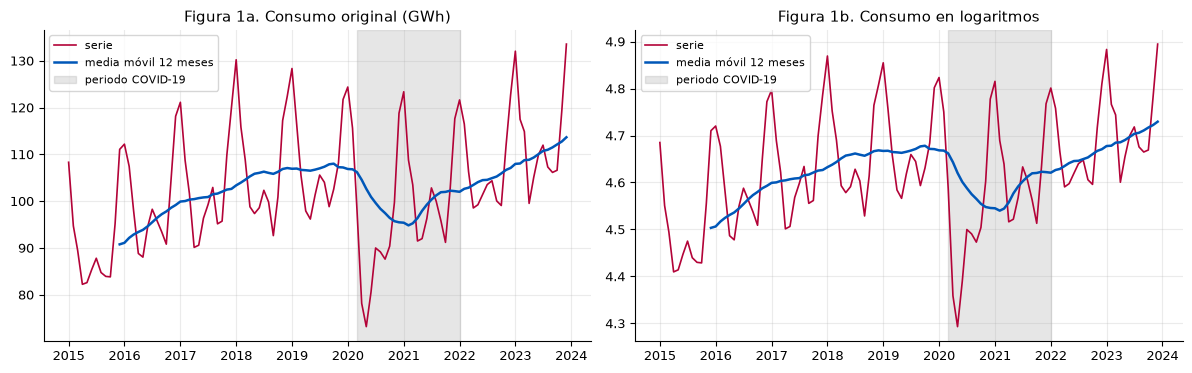

Lambda de Box-Cox (MLE)         : 0.11
Elasticidad (std anual vs media): 0.31  (0 = aditivo puro, 1 = multiplicativo puro)


In [5]:
# ============================================================
# 3.1 ¿Logaritmo o serie original?
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, serie, tit in zip(axes, [y_aj, ly],
                          ["Figura 1a. Consumo original (GWh)", "Figura 1b. Consumo en logaritmos"]):
    ax.plot(serie, color=ROJO, lw=1.2, label="serie")
    ax.plot(serie.rolling(12).mean(), color=AZUL, lw=1.8, label="media móvil 12 meses")
    ax.axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25, label="periodo COVID-19")
    ax.set_title(tit); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

# Box-Cox: lambda por máxima verosimilitud (sobre la serie de trabajo)
lam = float(stats.boxcox_normmax(y_aj.values, method="mle"))

# Elasticidad de la variabilidad anual respecto del nivel anual (sin 2020-2021, afectados por el COVID)
anual = y_aj.groupby(y_aj.index.year).agg(["mean", "std"]).drop(index=[2020, 2021])
elasticidad = float(np.polyfit(np.log(anual["mean"]), np.log(anual["std"]), 1)[0])

print(f"Lambda de Box-Cox (MLE)         : {lam:.2f}")
print(f"Elasticidad (std anual vs media): {elasticidad:.2f}  (0 = aditivo puro, 1 = multiplicativo puro)")

In [6]:
# ============================================================
# 3.1 (cont.) Decisión sobre la transformación
# ============================================================
if lam < 0.5:
    frase_lam = (f"El λ de Box-Cox es {c(lam)}, más cerca de 0 (logaritmo) que de 1 (sin transformar), "
                 "lo que respalda usar logaritmo.")
else:
    frase_lam = (f"El λ de Box-Cox es {c(lam)}, más cerca de 1 que de 0, así que la evidencia estadística por sí sola "
                 "no exige logaritmo; lo mantengo igualmente por las razones de interpretación y de coherencia con la Sumativa 1.")

display(Markdown(f"""
**Decisión 1 — Transformación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Trabajar con el **logaritmo natural** del consumo, `ly = log(consumo)`. |
| **Evidencia** | {frase_lam} La elasticidad entre variabilidad y nivel es {c(elasticidad)}, es decir, la variabilidad sube con el nivel pero menos que proporcionalmente. |
| **Alternativa descartada** | Modelar el consumo en GWh sin transformar. Habría funcionado, pero la estacionalidad y el efecto del COVID quedarían en GWh y no en porcentaje. |
| **Consecuencias** | Las diferencias del logaritmo se leen como variaciones porcentuales aproximadas. Los pronósticos se vuelven a convertir a GWh con la exponencial. Los efectos del COVID quedan expresados como porcentaje del nivel. |
"""))


**Decisión 1 — Transformación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Trabajar con el **logaritmo natural** del consumo, `ly = log(consumo)`. |
| **Evidencia** | El λ de Box-Cox es 0,11, más cerca de 0 (logaritmo) que de 1 (sin transformar), lo que respalda usar logaritmo. La elasticidad entre variabilidad y nivel es 0,31, es decir, la variabilidad sube con el nivel pero menos que proporcionalmente. |
| **Alternativa descartada** | Modelar el consumo en GWh sin transformar. Habría funcionado, pero la estacionalidad y el efecto del COVID quedarían en GWh y no en porcentaje. |
| **Consecuencias** | Las diferencias del logaritmo se leen como variaciones porcentuales aproximadas. Los pronósticos se vuelven a convertir a GWh con la exponencial. Los efectos del COVID quedan expresados como porcentaje del nivel. |


## 3.2 Tests de raíz unitaria (ADF y KPSS) para distintas diferenciaciones

Para decidir cuánto diferenciar no me quedo con un solo test. Aplico ADF y KPSS a la serie en nivel y a tres versiones diferenciadas, y las clasifico así:

- **Estacionaria:** ADF rechaza raíz unitaria (p < 0,05) y KPSS no rechaza estacionariedad (p ≥ 0,05). Los dos tests están de acuerdo.
- **No estacionaria:** ADF no rechaza (p ≥ 0,05) y KPSS rechaza (p < 0,05).
- **Discrepante o no concluyente:** los tests se contradicen o ninguno rechaza.

Detalles de implementación: en la serie en nivel uso la especificación con constante y tendencia (`ct`) porque hay tendencia, y en las series diferenciadas solo constante (`c`). El número de rezagos del ADF se elige con AIC y el del KPSS con la regla automática de `statsmodels`. Además de los tests, miro dos señales extra: la desviación estándar de la serie (si diferencio de más, esta sube) y la autocorrelación en el rezago 12 (si es alta y positiva, todavía queda estacionalidad sin remover).

In [7]:
# ============================================================
# 3.2 Tests ADF y KPSS sobre las combinaciones de diferenciación
# ============================================================
def evaluar(x, reg):
    """ADF + KPSS + señales auxiliares para una serie x."""
    x = x.dropna()
    a_est, a_p, a_lag = adfuller(x, regression=reg, autolag="AIC")[:3]
    k_est, k_p, k_lag = kpss(x, regression=reg, nlags="auto")[:3]
    if a_p < 0.05 and k_p >= 0.05:
        veredicto = "Estacionaria"
    elif a_p >= 0.05 and k_p < 0.05:
        veredicto = "No estacionaria"
    else:
        veredicto = "Discrepante / no concluyente"
    return {"n": len(x), "ADF estad.": a_est, "ADF p": a_p, "KPSS estad.": k_est, "KPSS p": k_p,
            "desv. est.": float(x.std()), "ACF(12)": float(acf(x, nlags=S)[S]), "veredicto": veredicto}

def tabla_pruebas(serie_log):
    """Evalúa (d, D) en {0,1} x {0,1} sobre una serie en logaritmos."""
    opc = {(0, 0): serie_log,
           (1, 0): serie_log.diff(),
           (0, 1): serie_log.diff(S),
           (1, 1): serie_log.diff().diff(S)}
    filas = {k: evaluar(v, "ct" if k == (0, 0) else "c") for k, v in opc.items()}
    return opc, filas

nombres = {(0, 0): "Nivel (log)", (1, 0): "d=1", (0, 1): "D=1 (lag 12)", (1, 1): "d=1 y D=1"}
opciones, pruebas = tabla_pruebas(ly)

tab_pruebas = pd.DataFrame(pruebas).T
tab_pruebas.index = [nombres[k] for k in pruebas]
# Referencia: la serie original sin logaritmo
ref = evaluar(y_aj, "ct")
tab_pruebas.loc["Nivel (original, GWh)"] = ref
tab_pruebas = tab_pruebas.loc[["Nivel (original, GWh)"] + [nombres[k] for k in pruebas]]
print("Tabla 1. Tests de raíz unitaria según el nivel de diferenciación (muestra 2015-2023)")
display(tab_pruebas.drop(columns="n").astype({"ADF estad.": float, "ADF p": float, "KPSS estad.": float,
                                              "KPSS p": float, "desv. est.": float, "ACF(12)": float}).round(3))
print("Nota: el p-valor de KPSS se reporta truncado entre 0,01 y 0,10 (límites de las tablas del test).")

Tabla 1. Tests de raíz unitaria según el nivel de diferenciación (muestra 2015-2023)


,ADF estad.,ADF p,KPSS estad.,KPSS p,desv. est.,ACF(12),veredicto
"Nivel (original, GWh)",-1.817,0.697,0.091,0.1,12.498,0.651,Discrepante / no concluyente
Nivel (log),-2.087,0.553,0.095,0.1,0.122,0.618,Discrepante / no concluyente
d=1,-2.908,0.044,0.040,0.1,0.080,0.744,Estacionaria
D=1 (lag 12),-2.846,0.052,0.192,0.1,0.081,-0.203,Discrepante / no concluyente
d=1 y D=1,-10.451,0.000,0.041,0.1,0.046,-0.330,Estacionaria


Nota: el p-valor de KPSS se reporta truncado entre 0,01 y 0,10 (límites de las tablas del test).


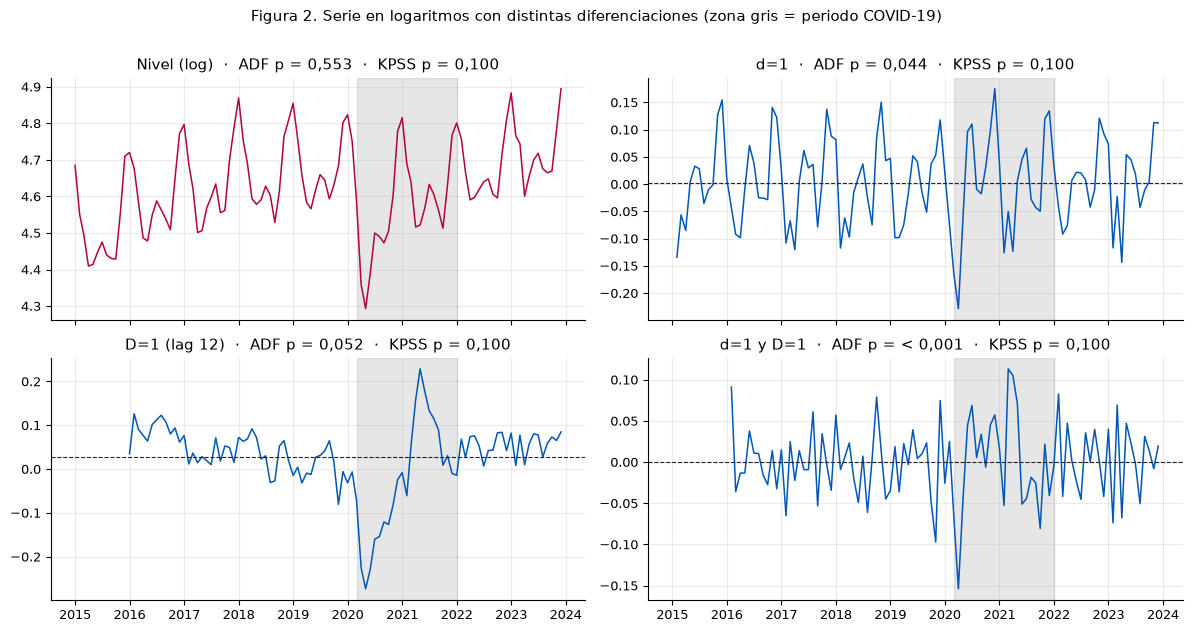

In [8]:
# ============================================================
# 3.2 (cont.) Figura de las series transformadas
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(12, 6.2), sharex=True)
for ax, (k, serie) in zip(axes.ravel(), opciones.items()):
    ax.plot(serie.dropna(), color=ROJO if k == (0, 0) else AZUL, lw=1.1)
    if k != (0, 0):
        ax.axhline(serie.mean(), color=NEGRO, lw=0.8, ls="--")
    ax.axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
    p_adf, p_kp = pruebas[k]["ADF p"], pruebas[k]["KPSS p"]
    ax.set_title(f"{nombres[k]}  ·  ADF p = {pv(p_adf)}  ·  KPSS p = {pv(p_kp)}")
fig.suptitle("Figura 2. Serie en logaritmos con distintas diferenciaciones (zona gris = periodo COVID-19)",
             y=1.01, fontsize=11)
plt.tight_layout(); plt.show()

## 3.3 Decisión sobre los órdenes de diferenciación

Para no decidir "a ojo", fijo la regla **antes** de mirar la decisión: elijo la **menor diferenciación posible** que cumpla las dos condiciones siguientes, probando en este orden: (d = 0, D = 0), (0, 1), (1, 0) y (1, 1).

1. Los dos tests la clasifican como **estacionaria** (ADF rechaza y KPSS no rechaza).
2. La autocorrelación en el rezago 12 es menor que 0,5, es decir, ya no queda una estacionalidad fuerte sin remover.

Si ninguna combinación cumple, uso (1, 1), que es lo que anticipé en la Sumativa 1. Como los tests pueden verse afectados por el quiebre del COVID-19, repito el mismo ejercicio solo con los años previos (2015-2019) como prueba de robustez.

In [9]:
# ============================================================
# 3.3 Regla de decisión y prueba de robustez (solo años previos al COVID-19)
# ============================================================
ORDEN_PRUEBA = [(0, 0), (0, 1), (1, 0), (1, 1)]

def elegir(filas):
    for k in ORDEN_PRUEBA:
        if filas[k]["veredicto"] == "Estacionaria" and filas[k]["ACF(12)"] < 0.5:
            return k, True
    return (1, 1), False

(d_sel, D_sel), cumple_regla = elegir(pruebas)

# Robustez: misma regla con la muestra 2015-01 a 2019-12 (antes del COVID-19)
_, pruebas_pre = tabla_pruebas(ly.loc[:"2019-12-01"])
(d_pre, D_pre), cumple_pre = elegir(pruebas_pre)

tab_rob = pd.DataFrame(pruebas_pre).T
tab_rob.index = [nombres[k] for k in pruebas_pre]
print("Tabla 2. Robustez: tests con la muestra 2015-2019 (sin COVID-19)")
display(tab_rob.drop(columns="n").astype({"ADF estad.": float, "ADF p": float, "KPSS estad.": float,
                                          "KPSS p": float, "desv. est.": float, "ACF(12)": float}).round(3))

# Texto con la decisión y su evidencia
f_sel = pruebas[(d_sel, D_sel)]
sd_cmp = {nombres[k]: pruebas[k]["desv. est."] for k in pruebas}
sobre_dif = ""
if (d_sel, D_sel) == (1, 1):
    # Se compara con las alternativas con una sola diferenciación para ver si hay sobrediferenciación
    sobre_dif = (f" La desviación estándar con d=1 y D=1 es {c(f_sel['desv. est.'], 4)}, frente a "
                 f"{c(pruebas[(0, 1)]['desv. est.'], 4)} con solo D=1 y {c(pruebas[(1, 0)]['desv. est.'], 4)} con solo d=1.")
razon_regla = ("cumple las dos condiciones de la regla" if cumple_regla else
               "ninguna combinación cumplió la regla, por lo que se aplicó la opción por defecto (1, 1)")
coincide = "coincide" if (d_pre, D_pre) == (d_sel, D_sel) else "no coincide"

display(Markdown(f"""
**Decisión 2 — Diferenciación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Usar **d = {d_sel}** (diferencia regular) y **D = {D_sel}** (diferencia estacional con s = {S}). Esta combinación {razon_regla}. |
| **Evidencia** | Con (d={d_sel}, D={D_sel}) el ADF da p = {pv(f_sel['ADF p'])} y el KPSS p = {pv(f_sel['KPSS p'])}, con veredicto **{f_sel['veredicto'].lower()}**; la autocorrelación en el rezago 12 es {c(f_sel['ACF(12)'])}.{sobre_dif} En el nivel (log), el ADF da p = {pv(pruebas[(0, 0)]['ADF p'])} y el KPSS p = {pv(pruebas[(0, 0)]['KPSS p'])}, con veredicto *{pruebas[(0, 0)]['veredicto'].lower()}*, y su ACF(12) es {c(pruebas[(0, 0)]['ACF(12)'])}. |
| **Robustez** | Con los datos de 2015-2019 la regla elige (d={d_pre}, D={D_pre}), lo que {coincide} con la decisión de la muestra completa. |
| **Alternativa descartada** | Menos diferenciación que la elegida deja tendencia o estacionalidad sin remover; más diferenciación infla la varianza y mete autocorrelación artificial (sobrediferenciación). |
| **Consecuencias** | Los modelos candidatos usarán d = {d_sel} y D = {D_sel}, con los efectos del COVID-19 como regresores. Cada observación de diferenciación consume datos: se pierden {d_sel + D_sel * S} observaciones al inicio de la serie. |
"""))

Tabla 2. Robustez: tests con la muestra 2015-2019 (sin COVID-19)


,ADF estad.,ADF p,KPSS estad.,KPSS p,desv. est.,ACF(12),veredicto
Nivel (log),-1.044,0.938,0.054,0.10,0.114,0.628,Discrepante / no concluyente
d=1,-2.476,0.121,0.059,0.10,0.076,0.706,Discrepante / no concluyente
D=1 (lag 12),-3.154,0.023,0.811,0.01,0.045,-0.203,Discrepante / no concluyente
d=1 y D=1,-9.255,0.000,0.126,0.10,0.039,-0.237,Estacionaria



**Decisión 2 — Diferenciación.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Usar **d = 1** (diferencia regular) y **D = 1** (diferencia estacional con s = 12). Esta combinación cumple las dos condiciones de la regla. |
| **Evidencia** | Con (d=1, D=1) el ADF da p = < 0,001 y el KPSS p = 0,100, con veredicto **estacionaria**; la autocorrelación en el rezago 12 es -0,33. La desviación estándar con d=1 y D=1 es 0,0465, frente a 0,0806 con solo D=1 y 0,0800 con solo d=1. En el nivel (log), el ADF da p = 0,553 y el KPSS p = 0,100, con veredicto *discrepante / no concluyente*, y su ACF(12) es 0,62. |
| **Robustez** | Con los datos de 2015-2019 la regla elige (d=1, D=1), lo que coincide con la decisión de la muestra completa. |
| **Alternativa descartada** | Menos diferenciación que la elegida deja tendencia o estacionalidad sin remover; más diferenciación infla la varianza y mete autocorrelación artificial (sobrediferenciación). |
| **Consecuencias** | Los modelos candidatos usarán d = 1 y D = 1, con los efectos del COVID-19 como regresores. Cada observación de diferenciación consume datos: se pierden 13 observaciones al inicio de la serie. |


## 3.4 Verificación de la estacionariedad resultante

Una vez elegida la diferenciación, verifico visualmente y con los tests que la serie resultante sea estacionaria: reviso que la media sea constante y que la variabilidad no cambie. Miro la media y la desviación móviles de 12 meses de la serie diferenciada. El quiebre del COVID-19 es el único punto en que se espera un comportamiento distinto.

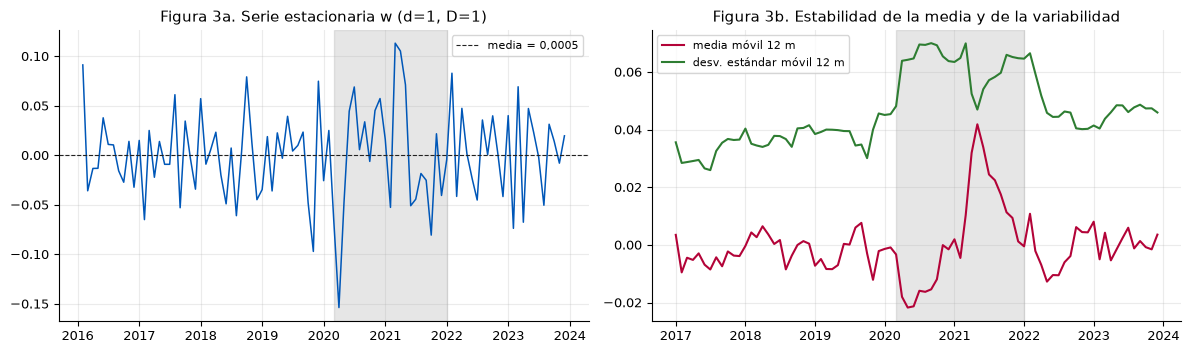


**Lectura (Figuras 3a y 3b).** La serie diferenciada oscila alrededor de 0,001 (media de toda la muestra), sin la tendencia ni los ciclos anuales que tenía el nivel. Los tests confirman el resultado: ADF con p = < 0,001 y KPSS con p = 0,100 (estacionaria).
La desviación estándar de w es 0,0399 fuera del periodo COVID-19 y 0,0638 dentro de él. Dentro del periodo COVID-19 la variabilidad es mayor, y por eso incorporo el COVID-19 como regresor en los modelos (sección 4).
**Conclusión de la sección 3:** la serie se vuelve estacionaria con log + d = 1 + D = 1, y esa es la base para identificar los modelos.


In [10]:
# ============================================================
# 3.4 Verificación: serie diferenciada elegida (w), media y desviación móviles
# ============================================================
w = opciones[(d_sel, D_sel)].dropna()
w.name = "w"

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(w, color=AZUL, lw=1.1)
axes[0].axhline(w.mean(), color=NEGRO, lw=0.8, ls="--", label=f"media = {c(w.mean(), 4)}")
axes[0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0].set_title(f"Figura 3a. Serie estacionaria w (d={d_sel}, D={D_sel})"); axes[0].legend(fontsize=8)
axes[1].plot(w.rolling(12).mean(), color=ROJO, label="media móvil 12 m")
axes[1].plot(w.rolling(12).std(), color=VERDE, label="desv. estándar móvil 12 m")
axes[1].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[1].set_title("Figura 3b. Estabilidad de la media y de la variabilidad"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Comparación de la variabilidad dentro y fuera del COVID-19
en_cov = (w.index >= COVID_INI) & (w.index <= COVID_FIN)
sd_fuera, sd_dentro = float(w[~en_cov].std()), float(w[en_cov].std())
p_adf, p_kp = pruebas[(d_sel, D_sel)]["ADF p"], pruebas[(d_sel, D_sel)]["KPSS p"]

display(Markdown(f"""
**Lectura (Figuras 3a y 3b).** La serie diferenciada oscila alrededor de {c(w.mean(), 3)} (media de toda la muestra), sin la tendencia ni los ciclos anuales que tenía el nivel. Los tests confirman el resultado: ADF con p = {pv(p_adf)} y KPSS con p = {pv(p_kp)} ({pruebas[(d_sel, D_sel)]['veredicto'].lower()}).
La desviación estándar de w es {c(sd_fuera, 4)} fuera del periodo COVID-19 y {c(sd_dentro, 4)} dentro de él. {'Dentro del periodo COVID-19 la variabilidad es mayor, y por eso incorporo el COVID-19 como regresor en los modelos (sección 4).' if sd_dentro > sd_fuera else 'La variabilidad es parecida dentro y fuera del COVID-19.'}
**Conclusión de la sección 3:** la serie se vuelve estacionaria con log + d = {d_sel} + D = {D_sel}, y esa es la base para identificar los modelos.
"""))

> **Interpretación del autor — Sección 3 (estacionariedad).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Por qué ADF y KPSS se usan juntos y qué significaría que se contradijeran en mi serie?
> - ¿Qué diferencia vi entre la serie en nivel y la serie diferenciada, y qué hizo cada diferencia (d y D)?
> - ¿Cómo pudo influir el COVID-19 en los tests y por qué igual me quedé con esa decisión?
>
> **[COMPLETAR]**

# 4. Identificación y estimación de modelos (AR, MA, ARMA, ARIMA, SARIMA)

Con la serie ya estacionaria (log + d + D), el siguiente paso es la **identificación**: mirar la ACF y la PACF de la serie diferenciada para proponer los órdenes p, q, P y Q. Después **estimo** los modelos por máxima verosimilitud con `statsmodels` (Seabold y Perktold, 2010).

## 4.1 Lectura de la ACF y la PACF

Uso estas reglas de lectura (Box et al., 2015; Hyndman y Athanasopoulos, 2021):

| Si en la serie estacionaria se ve… | entonces sugiere… |
|---|---|
| PACF con corte claro después del rezago *p* y ACF que decae | un componente **AR(p)** |
| ACF con corte claro después del rezago *q* y PACF que decae | un componente **MA(q)** |
| Ambas decaen sin cortar | un modelo mixto **ARMA(p, q)** |
| Pico significativo en el rezago 12 de la ACF | un término **MA estacional (Q = 1)** |
| Pico significativo en el rezago 12 de la PACF (sin pico en la ACF) | un término **AR estacional (P = 1)** |

La banda de significancia al 95 % es aproximadamente ±1,96/√n. Miro hasta 24 rezagos (dos ciclos anuales).

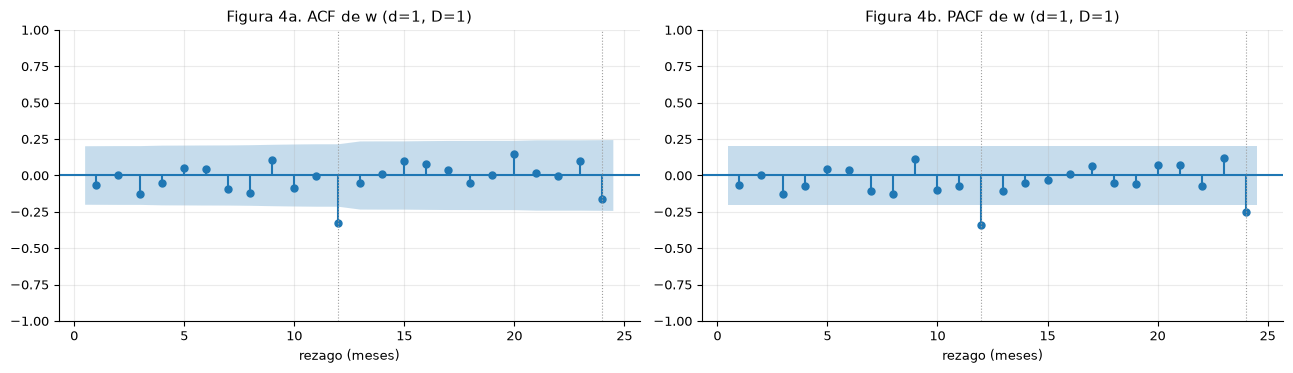

,ACF,PACF,ACF signif.,PACF signif.
rezago,,,,
1,-0.065,-0.065,False,False
2,0.007,0.003,False,False
3,-0.125,-0.125,False,False
4,-0.054,-0.072,False,False
6,0.042,0.034,False,False
12,-0.330,-0.339,True,True
24,-0.160,-0.254,False,True


n = 95; banda 95% = ±0.201
Rezagos ACF significativos : [12]
Rezagos PACF significativos: [12, 24]


In [11]:
# ============================================================
# 4.1 ACF y PACF de la serie estacionaria w
# ============================================================
NL = 24
r_w = acf(w, nlags=NL)
p_w = pacf(w, nlags=NL, method="ywm")
banda = 1.96 / np.sqrt(len(w))
sig_acf = [k for k in range(1, NL + 1) if abs(r_w[k]) > banda]
sig_pacf = [k for k in range(1, NL + 1) if abs(p_w[k]) > banda]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plot_acf(w, lags=NL, ax=axes[0], zero=False, title=f"Figura 4a. ACF de w (d={d_sel}, D={D_sel})")
plot_pacf(w, lags=NL, ax=axes[1], zero=False, method="ywm", title=f"Figura 4b. PACF de w (d={d_sel}, D={D_sel})")
for ax in axes:
    ax.set_xlabel("rezago (meses)")
    for k in (12, 24):
        ax.axvline(k, color=GRIS, ls=":", lw=0.8)
plt.tight_layout(); plt.show()

clave = [1, 2, 3, 4, 6, 12, 24]
tab_cor = pd.DataFrame({"ACF": r_w[clave], "PACF": p_w[clave]}, index=pd.Index(clave, name="rezago")).round(3)
tab_cor["ACF signif."] = np.abs(r_w[clave]) > banda
tab_cor["PACF signif."] = np.abs(p_w[clave]) > banda
display(tab_cor)
print(f"n = {len(w)}; banda 95% = ±{banda:.3f}")
print("Rezagos ACF significativos :", sig_acf)
print("Rezagos PACF significativos:", sig_pacf)

In [12]:
# ============================================================
# 4.1 (cont.) Órdenes sugeridos por la evidencia (regla explícita)
# ============================================================
def mayor_corto(sig, tope=3):
    """Mayor rezago significativo entre 1 y `tope` (0 si no hay)."""
    cortos = [k for k in sig if k <= tope]
    return max(cortos) if cortos else 0

p_sug = min(mayor_corto(sig_pacf), 2)            # AR no estacional (se limita a 2 para no sobreajustar)
q_sug = min(mayor_corto(sig_acf), 2)             # MA no estacional
Q_sug = int(S in sig_acf)                         # MA estacional si la ACF es significativa en 12
P_sug = int((S in sig_pacf) and (S not in sig_acf))   # AR estacional si solo la PACF lo es

pico12_acf = r_w[S]; pico12_pacf = p_w[S]
display(Markdown(f"""
**Lectura (Figuras 4a y 4b).**

- **Parte no estacional.** Rezagos significativos de la ACF: {sig_acf if sig_acf else 'ninguno'}. Rezagos significativos de la PACF: {sig_pacf if sig_pacf else 'ninguno'}. En los primeros tres rezagos, el último rezago significativo de la PACF es {mayor_corto(sig_pacf)} y el de la ACF es {mayor_corto(sig_acf)}, lo que sugiere p = {p_sug} y q = {q_sug}.
- **Parte estacional.** En el rezago 12 la ACF vale {c(pico12_acf)} ({'significativa' if S in sig_acf else 'no significativa'}) y la PACF vale {c(pico12_pacf)} ({'significativa' if S in sig_pacf else 'no significativa'}). Eso sugiere P = {P_sug} y Q = {Q_sug}.
- **Resumen:** la evidencia apunta a un **SARIMA({p_sug},{d_sel},{q_sug})({P_sug},{D_sel},{Q_sug})₁₂** como candidato principal. Como la lectura de correlogramas con pocos datos es incierta (n = {len(w)}), pruebo también modelos vecinos y los modelos de referencia de cada familia.
"""))


**Lectura (Figuras 4a y 4b).**

- **Parte no estacional.** Rezagos significativos de la ACF: [12]. Rezagos significativos de la PACF: [12, 24]. En los primeros tres rezagos, el último rezago significativo de la PACF es 0 y el de la ACF es 0, lo que sugiere p = 0 y q = 0.
- **Parte estacional.** En el rezago 12 la ACF vale -0,33 (significativa) y la PACF vale -0,34 (significativa). Eso sugiere P = 0 y Q = 1.
- **Resumen:** la evidencia apunta a un **SARIMA(0,1,0)(0,1,1)₁₂** como candidato principal. Como la lectura de correlogramas con pocos datos es incierta (n = 95), pruebo también modelos vecinos y los modelos de referencia de cada familia.


## 4.2 Modelos candidatos

Propongo candidatos de todas las familias que pide la evaluación. Para que la comparación sea justa, todos incluyen los dos regresores del COVID-19 (`covid` y `covid_pico`):

- **AR y MA:** se aplican sobre la serie ya diferenciada (con los mismos d y D elegidos), así que modelan la dependencia de corto plazo sin parte estacional propia.
- **ARMA:** combinación de ambos, también sobre la serie diferenciada.
- **ARIMA (sin estacionalidad):** referencia que solo diferencia de forma regular (D = 0) y no modela el ciclo anual. Se espera que rinda peor, y sirve para medir cuánto aporta la parte estacional.
- **SARIMA:** modelos con parte estacional. Incluyo el modelo sugerido por la ACF/PACF (sección 4.1), el clásico "modelo de líneas aéreas" SARIMA(0,d,1)(0,D,1)₁₂ y variantes vecinas con distinta complejidad.

**Sobre la constante.** Cuando d + D = 0 incluyo una constante; cuando d + D = 1, una tendencia lineal (que equivale a un "drift", es decir, un crecimiento medio constante); cuando d + D = 2 no incluyo término determinista, porque la doble diferencia ya lo elimina.

In [13]:
# ============================================================
# 4.2 Definición de los modelos candidatos
# ============================================================
# Cada candidato: (familia, origen, p, d, q, P, D, Q)
d, D = d_sel, D_sel
d_arima = max(d, 1)       # el ARIMA de referencia no tiene parte estacional, así que necesita al menos d = 1

candidatos = [
    ("AR",     "clásico",  1, d, 0, 0, D, 0),
    ("AR",     "clásico",  2, d, 0, 0, D, 0),
    ("MA",     "clásico",  0, d, 1, 0, D, 0),
    ("MA",     "clásico",  0, d, 2, 0, D, 0),
    ("ARMA",   "clásico",  1, d, 1, 0, D, 0),
    ("ARMA",   "clásico",  2, d, 1, 0, D, 0),
    ("ARIMA",  "referencia sin estacionalidad", 1, d_arima, 1, 0, 0, 0),
    ("ARIMA",  "referencia sin estacionalidad", 2, d_arima, 1, 0, 0, 0),
    ("SARIMA", "clásico",  1, d, 0, 1, D, 0),
    ("SARIMA", "clásico",  0, d, 1, 0, D, 1),       # "airline"
    ("SARIMA", "clásico",  1, d, 0, 0, D, 1),
    ("SARIMA", "clásico",  1, d, 1, 0, D, 1),
    ("SARIMA", "clásico",  2, d, 0, 0, D, 1),
    ("SARIMA", "clásico",  1, d, 1, 1, D, 1),
    ("SARIMA", "clásico",  2, d, 1, 0, D, 1),
]
# Candidato sugerido por la ACF/PACF: si ya estaba en la lista solo se etiqueta; si no, se agrega
sug = ("SARIMA", "sugerido por ACF/PACF", p_sug, d, q_sug, P_sug, D, Q_sug)
if sug[2:] in [c_[2:] for c_ in candidatos]:
    candidatos = [(c_[0], "sugerido por ACF/PACF" if c_[2:] == sug[2:] else c_[1], *c_[2:]) for c_ in candidatos]
else:
    candidatos.insert(8, sug)

def nombre_modelo(fam, p, d_, q, P, D_, Q):
    """Nombre legible del modelo según su familia."""
    if fam == "AR":
        return f"AR({p}) [d={d_}, D={D_}]"
    if fam == "MA":
        return f"MA({q}) [d={d_}, D={D_}]"
    if fam == "ARMA":
        return f"ARMA({p},{q}) [d={d_}, D={D_}]"
    if fam == "ARIMA":
        return f"ARIMA({p},{d_},{q})"
    return f"SARIMA({p},{d_},{q})({P},{D_},{Q})[{S}]"

NOMBRES = {c_[2:]: nombre_modelo(c_[0], *c_[2:]) for c_ in candidatos}   # (p,d,q,P,D,Q) -> nombre

tab_cand = pd.DataFrame(
    [{"modelo": NOMBRES[c_[2:]], "familia": c_[0], "origen": c_[1],
      "p": c_[2], "d": c_[3], "q": c_[4], "P": c_[5], "D": c_[6], "Q": c_[7]} for c_ in candidatos]
).set_index("modelo")
print(f"Tabla 3. {len(tab_cand)} modelos candidatos")
display(tab_cand)

Tabla 3. 16 modelos candidatos


,familia,origen,p,d,q,P,D,Q
modelo,,,,,,,,
"AR(1) [d=1, D=1]",AR,clásico,1,1,0,0,1,0
"AR(2) [d=1, D=1]",AR,clásico,2,1,0,0,1,0
"MA(1) [d=1, D=1]",MA,clásico,0,1,1,0,1,0
"MA(2) [d=1, D=1]",MA,clásico,0,1,2,0,1,0
"ARMA(1,1) [d=1, D=1]",ARMA,clásico,1,1,1,0,1,0
"ARMA(2,1) [d=1, D=1]",ARMA,clásico,2,1,1,0,1,0
"ARIMA(1,1,1)",ARIMA,referencia sin estacionalidad,1,1,1,0,0,0
"ARIMA(2,1,1)",ARIMA,referencia sin estacionalidad,2,1,1,0,0,0
"SARIMA(0,1,0)(0,1,1)[12]",SARIMA,sugerido por ACF/PACF,0,1,0,0,1,1


## 4.3 Estimación

Estimo cada candidato con `statsmodels.tsa.arima.model.ARIMA` (máxima verosimilitud mediante filtro de Kalman). Cada modelo se estima dos veces: (a) con la muestra de entrenamiento 2015-2022, para pronosticar 2023 y obtener las métricas de validación, y (b) con los 108 meses de 2015-2023, para obtener AIC, BIC y los residuos. Registro cuántos parámetros ARMA resultan no significativos (p ≥ 0,05) como señal de que el modelo puede ser más complejo de lo necesario.

In [14]:
# ============================================================
# 4.3 Estimación de todos los candidatos
# ============================================================
def tendencia(d_, D_):
    """Término determinista compatible con el orden de diferenciación."""
    k = d_ + D_
    return "c" if k == 0 else ("t" if k == 1 else "n")

def ajustar(serie, exog, spec):
    """Ajusta un modelo ARIMA/SARIMA con regresores opcionales. spec = (p, d, q, P, D, Q)."""
    p, d_, q, P, D_, Q = spec
    est = (P, D_, Q, S) if (P or D_ or Q) else (0, 0, 0, 0)
    modelo = ARIMA(serie, exog=exog, order=(p, d_, q), seasonal_order=est, trend=tendencia(d_, D_))
    return modelo.fit()

def pronosticar(res, pasos, exog_f):
    """Pronóstico en GWh (se invierte el logaritmo) con su intervalo de 95 %."""
    fc = res.get_forecast(steps=pasos, exog=exog_f)
    ic = fc.conf_int(alpha=0.05)
    ic = np.asarray(ic)
    return np.exp(np.asarray(fc.predicted_mean)), np.exp(ic[:, 0]), np.exp(ic[:, 1])

ent_val = ly.loc[:"2022-12-01"]                      # entrenamiento de la validación
X_ent_val = X.loc[ent_val.index]
idx_val = ly.loc["2023-01-01":].index                # 2023
X_val = X.loc[idx_val]

resultados = {}
filas = []
for fam, origen, p, d_, q, P, D_, Q in candidatos:
    spec = (p, d_, q, P, D_, Q)
    nom = NOMBRES[spec]
    try:
        r_full = ajustar(ly, X, spec)                # 2015-2023 (AIC, BIC, residuos)
        r_val = ajustar(ent_val, X_ent_val, spec)    # 2015-2022 (pronóstico 2023)
        pred_val, _, _ = pronosticar(r_val, 12, X_val)
    except Exception as e:                           # un modelo que no converge se informa y se descarta
        print(f"[aviso] {nom} no se pudo estimar: {type(e).__name__}")
        continue
    pv_arma = r_full.pvalues[[n for n in r_full.pvalues.index if n.startswith(("ar.", "ma."))]]
    resultados[nom] = {"spec": spec, "full": r_full, "val": r_val,
                       "pred_val": pd.Series(pred_val, index=idx_val), "k_arma": len(pv_arma)}
    filas.append({"modelo": nom, "familia": fam, "p": p, "d": d_, "q": q, "P": P, "D": D_, "Q": Q,
                  "k": len(r_full.params), "parámetros ARMA": len(pv_arma),
                  "ARMA no signif.": int((pv_arma >= 0.05).sum()),
                  "logL": r_full.llf, "AIC": r_full.aic, "BIC": r_full.bic})

tabla = pd.DataFrame(filas).set_index("modelo")
print(f"Tabla 4. Estimación de {len(tabla)} modelos (muestra 2015-2023, n = {len(ly)})")
display(tabla[["familia", "k", "parámetros ARMA", "ARMA no signif.", "logL", "AIC", "BIC"]].round(2))

Tabla 4. Estimación de 16 modelos (muestra 2015-2023, n = 108)


,familia,k,parámetros ARMA,ARMA no signif.,logL,AIC,BIC
modelo,,,,,,,
"AR(1) [d=1, D=1]",AR,4,1,0,179.72,-351.45,-341.23
"AR(2) [d=1, D=1]",AR,5,2,1,179.85,-349.70,-336.93
"MA(1) [d=1, D=1]",MA,4,1,0,180.03,-352.05,-341.84
"MA(2) [d=1, D=1]",MA,5,2,1,180.03,-350.05,-337.28
"ARMA(1,1) [d=1, D=1]",ARMA,5,2,2,180.03,-350.05,-337.28
"ARMA(2,1) [d=1, D=1]",ARMA,6,3,0,182.09,-352.17,-336.85
"ARIMA(1,1,1)",ARIMA,6,2,2,135.88,-259.75,-243.71
"ARIMA(2,1,1)",ARIMA,7,3,0,152.41,-290.82,-272.11
"SARIMA(0,1,0)(0,1,1)[12]",SARIMA,4,1,1,190.01,-372.03,-361.81


In [15]:
# ============================================================
# 4.3 (cont.) Efecto estimado del COVID-19 en el modelo sugerido
# ============================================================
nom_ref = NOMBRES[(p_sug, d_sel, q_sug, P_sug, D_sel, Q_sug)]
r_ref = resultados[nom_ref]["full"]
coef = pd.DataFrame({"coeficiente": r_ref.params, "error estándar": r_ref.bse, "valor-p": r_ref.pvalues}).round(4)
print(f"Tabla 5. Coeficientes del modelo {nom_ref}")
display(coef)

b_cov, b_pico = r_ref.params["covid"], r_ref.params["covid_pico"]
neg_sig = (b_cov < 0 and b_pico < 0 and r_ref.pvalues["covid"] < 0.05 and r_ref.pvalues["covid_pico"] < 0.05)
cierre_covid = ("Ambos coeficientes son negativos y significativos, lo que concuerda con lo visto en la Sumativa 1: el consumo cayó con el COVID-19 y tocó fondo en el trimestre abril-junio de 2020."
                if neg_sig else
                "Al menos uno de los coeficientes no es significativo o no es negativo, es decir, la estimación del efecto del COVID-19 es imprecisa con estos datos (hay pocos meses afectados), aunque se mantiene en el modelo por la evidencia de la Sumativa 1.")
display(Markdown(f"""
**Lectura.** Se estimaron {len(tabla)} modelos. En el modelo {nom_ref}, el indicador del periodo COVID-19 vale {c(b_cov, 3)} (≈ {c(100 * (np.exp(b_cov) - 1), 1)} % sobre el nivel esperado, valor-p {pv(r_ref.pvalues['covid'])}) y el del mínimo de abril a junio de 2020 vale {c(b_pico, 3)} (≈ {c(100 * (np.exp(b_pico) - 1), 1)} % adicional, valor-p {pv(r_ref.pvalues['covid_pico'])}). {cierre_covid}
"""))

Tabla 5. Coeficientes del modelo SARIMA(0,1,0)(0,1,1)[12]


,coeficiente,error estándar,valor-p
covid,-0.0764,0.0391,0.0507
covid_pico,-0.1001,0.0230,0.0000
ma.S.L12,-0.9862,3.3910,0.7712
sigma2,0.0008,0.0028,0.7639



**Lectura.** Se estimaron 16 modelos. En el modelo SARIMA(0,1,0)(0,1,1)[12], el indicador del periodo COVID-19 vale -0,076 (≈ -7,4 % sobre el nivel esperado, valor-p 0,051) y el del mínimo de abril a junio de 2020 vale -0,100 (≈ -9,5 % adicional, valor-p < 0,001). Al menos uno de los coeficientes no es significativo o no es negativo, es decir, la estimación del efecto del COVID-19 es imprecisa con estos datos (hay pocos meses afectados), aunque se mantiene en el modelo por la evidencia de la Sumativa 1.


> **Interpretación del autor — Sección 4 (identificación y estimación).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Qué vi en la ACF y la PACF (cortes, decaimientos, rezago 12) y qué modelos me sugirió cada patrón?
> - ¿Por qué incluí modelos de varias familias y qué espero aprender de compararlas?
> - ¿Qué dicen los coeficientes del COVID-19 y qué tan confiable me parece esa estimación?
>
> **[COMPLETAR]**

# 5. Selección y comparación de modelos

Comparo los modelos con dos tipos de evidencia: (i) **criterios de información** (AIC y BIC) calculados con toda la muestra, y (ii) **métricas de pronóstico fuera de muestra**, usando los modelos estimados hasta 2022 para pronosticar los 12 meses de 2023. Las métricas, calculadas en GWh, son:

- **RMSE:** raíz del error cuadrático medio (penaliza más los errores grandes).
- **MAE:** error absoluto medio.
- **MAPE:** error porcentual absoluto medio.
- **MASE:** error absoluto medio dividido por el error de un pronóstico ingenuo estacional dentro de la muestra de entrenamiento (Hyndman y Koehler, 2006). Un MASE menor que 1 significa que el modelo supera al ingenuo estacional.

Como referencia incluyo el **pronóstico ingenuo estacional** (cada mes igual al mismo mes del año anterior), que es lo mínimo que cualquier modelo debería superar.

**Precaución con AIC y BIC.** Estos criterios solo se pueden comparar entre modelos estimados sobre la **misma serie diferenciada** (mismos d y D), porque cambian las observaciones que entran a la verosimilitud. Por eso el ranking usa solo los modelos con los mismos d y D elegidos en la sección 3, y el ARIMA sin estacionalidad se evalúa únicamente con las métricas de pronóstico.

In [16]:
# ============================================================
# 5.1 Métricas de pronóstico de validación (2023) y del ingenuo estacional
# ============================================================
def metricas(real, pred, escala):
    real = np.asarray(real, float); pred = np.asarray(pred, float)
    err = pred - real
    return {"RMSE": float(np.sqrt(np.mean(err ** 2))),
            "MAE": float(np.mean(np.abs(err))),
            "MAPE": float(np.mean(np.abs(err) / real) * 100),
            "MASE": float(np.mean(np.abs(err)) / escala),
            "sesgo %": float(np.mean(err) / np.mean(real) * 100)}

real_val = y_aj.loc["2023-01-01":"2023-12-01"]
escala_val = float(y_aj.loc[:"2022-12-01"].diff(S).dropna().abs().mean())     # MAE del ingenuo estacional en entrenamiento
naive_val = pd.Series(y_aj.loc["2022-01-01":"2022-12-01"].values, index=real_val.index)

m_val = pd.DataFrame({nom: metricas(real_val, r["pred_val"], escala_val) for nom, r in resultados.items()}).T
m_val.loc["Ingenuo estacional"] = metricas(real_val, naive_val, escala_val)
m_val.columns = [f"{k}_val" if k != "sesgo %" else "sesgo_val %" for k in m_val.columns]

tabla = tabla.join(m_val.drop(index="Ingenuo estacional"))
print(f"Tabla 6. Métricas de pronóstico en validación (2023, GWh); escala MASE = {escala_val:.2f} GWh")
display(m_val.round(3))

Tabla 6. Métricas de pronóstico en validación (2023, GWh); escala MASE = 6.48 GWh


,RMSE_val,MAE_val,MAPE_val,MASE_val,sesgo_val %
"AR(1) [d=1, D=1]",9.229,8.592,7.561,1.326,-7.559
"AR(2) [d=1, D=1]",9.346,8.701,7.659,1.343,-7.655
"MA(1) [d=1, D=1]",9.396,8.758,7.709,1.352,-7.706
"MA(2) [d=1, D=1]",9.577,8.950,7.879,1.381,-7.874
"ARMA(1,1) [d=1, D=1]",9.898,9.298,8.185,1.435,-8.180
"ARMA(2,1) [d=1, D=1]",7.124,6.507,5.711,1.004,-5.725
"ARIMA(1,1,1)",17.711,16.155,14.848,2.493,12.685
"ARIMA(2,1,1)",8.018,6.115,5.240,0.944,-0.835
"SARIMA(0,1,0)(0,1,1)[12]",7.338,6.948,6.156,1.072,-6.113
"SARIMA(1,1,0)(1,1,0)[12]",7.220,6.541,5.760,1.009,-5.755


Tabla 7. Ranking de los modelos comparables (puntaje = ranking promedio en AIC, BIC, RMSE y MASE; menor es mejor)


,familia,k,AIC,BIC,RMSE_val,MAE_val,MAPE_val,MASE_val,puntaje
modelo,,,,,,,,,
"SARIMA(0,1,1)(0,1,1)[12]",SARIMA,5,-391.076,-378.307,5.752,5.235,4.644,0.808,2.50
"SARIMA(1,1,1)(0,1,1)[12]",SARIMA,6,-389.360,-374.037,5.697,5.176,4.591,0.799,2.75
"SARIMA(1,1,1)(1,1,1)[12]",SARIMA,7,-386.920,-369.043,5.667,5.143,4.561,0.794,3.50
"SARIMA(2,1,1)(0,1,1)[12]",SARIMA,7,-385.571,-367.694,5.396,4.887,4.332,0.754,3.50
"SARIMA(2,1,0)(0,1,1)[12]",SARIMA,6,-388.650,-373.326,6.085,5.582,4.952,0.861,4.25
"SARIMA(1,1,0)(0,1,1)[12]",SARIMA,5,-388.572,-375.803,6.296,5.825,5.166,0.899,4.50
"SARIMA(0,1,0)(0,1,1)[12]",SARIMA,4,-372.026,-361.810,7.338,6.948,6.156,1.072,8.00
"SARIMA(1,1,0)(1,1,0)[12]",SARIMA,5,-363.629,-350.860,7.220,6.541,5.760,1.009,8.00
"ARMA(2,1) [d=1, D=1]",ARMA,6,-352.175,-336.852,7.124,6.507,5.711,1.004,9.25


Modelos no comparables por AIC/BIC (distinta diferenciación); se juzgan solo por pronóstico:


,familia,RMSE_val,MAE_val,MAPE_val,MASE_val
modelo,,,,,
"ARIMA(1,1,1)",ARIMA,17.711,16.155,14.848,2.493
"ARIMA(2,1,1)",ARIMA,8.018,6.115,5.240,0.944


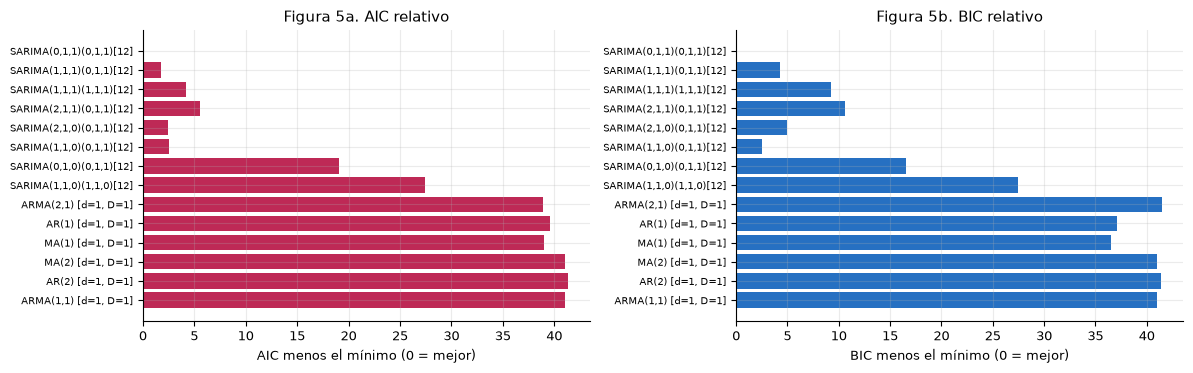

In [17]:
# ============================================================
# 5.2 Tabla comparativa y ranking (solo modelos comparables por diferenciación)
# ============================================================
tabla["comparable"] = (tabla["d"] == d_sel) & (tabla["D"] == D_sel)
cols_rank = ["AIC", "BIC", "RMSE_val", "MASE_val"]
tabla["puntaje"] = np.nan
tabla.loc[tabla["comparable"], "puntaje"] = tabla.loc[tabla["comparable"], cols_rank].rank().mean(axis=1)

ranking = (tabla[tabla["comparable"]]
           .sort_values(["puntaje", "BIC"])
           [["familia", "k", "AIC", "BIC", "RMSE_val", "MAE_val", "MAPE_val", "MASE_val", "puntaje"]])
print("Tabla 7. Ranking de los modelos comparables (puntaje = ranking promedio en AIC, BIC, RMSE y MASE; menor es mejor)")
display(ranking.round(3))

fuera = tabla[~tabla["comparable"]][["familia", "RMSE_val", "MAE_val", "MAPE_val", "MASE_val"]]
print("Modelos no comparables por AIC/BIC (distinta diferenciación); se juzgan solo por pronóstico:")
display(fuera.round(3))

# Gráfico: AIC y BIC de los modelos comparables
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
orden_g = ranking.index.tolist()
for ax, col, color in zip(axes, ["AIC", "BIC"], [ROJO, AZUL]):
    vals = ranking.loc[orden_g, col]
    ax.barh(range(len(vals)), vals.values - vals.min(), color=color, alpha=0.85)
    ax.set_yticks(range(len(vals))); ax.set_yticklabels(orden_g, fontsize=7.5)
    ax.invert_yaxis(); ax.set_xlabel(f"{col} menos el mínimo (0 = mejor)")
    ax.set_title(f"Figura 5{'a' if col == 'AIC' else 'b'}. {col} relativo")
plt.tight_layout(); plt.show()

In [18]:
# ============================================================
# 5.3 Elección: mejor puntaje que además pase el test de Ljung-Box
# ============================================================
BURN = d_sel + D_sel * S                               # primeras observaciones afectadas por la diferenciación
orden_modelos = ranking.index.tolist()

filas_lb = []
seleccion = None
for nom in orden_modelos:
    r_ = resultados[nom]
    e_ = r_["full"].resid.iloc[BURN:]
    lb_ = acorr_ljungbox(e_, lags=[12, 24], model_df=r_["k_arma"], return_df=True)
    ok_ = bool((lb_["lb_pvalue"] > 0.05).all())
    filas_lb.append({"modelo": nom, "puntaje": ranking.loc[nom, "puntaje"],
                     "LB p (rezago 12)": float(lb_["lb_pvalue"].iloc[0]),
                     "LB p (rezago 24)": float(lb_["lb_pvalue"].iloc[1]),
                     "pasa Ljung-Box": ok_})
    if ok_ and seleccion is None:
        seleccion = nom
hay_modelo_valido = seleccion is not None
if seleccion is None:                                   # si ninguno pasa, se queda el de mejor puntaje
    seleccion = orden_modelos[0]

tab_lb = pd.DataFrame(filas_lb).set_index("modelo")
print("Tabla 8. Modelos en orden de ranking y su prueba de Ljung-Box (se elige el primero que la pasa)")
display(tab_lb.head(8).round(3))

mejor_rank = orden_modelos[0]
sel = resultados[seleccion]
spec_sel = sel["spec"]
res_sel = sel["full"]
fila_sel = tabla.loc[seleccion]
fila_naive = m_val.loc["Ingenuo estacional"]
mejora_rmse = 100 * (1 - fila_sel["RMSE_val"] / fila_naive["RMSE_val"])
dif_bic = float(fila_sel["BIC"] - ranking["BIC"].min())
dif_aic = float(fila_sel["AIC"] - ranking["AIC"].min())
arimas = tabla[tabla["familia"] == "ARIMA"]
if len(arimas):
    texto_alt = (f"El mejor ARIMA sin parte estacional (D = 0) tuvo RMSE de validación = {c(arimas['RMSE_val'].min())} GWh, frente a {c(fila_sel['RMSE_val'])} GWh del modelo elegido. "
                 f"Los otros {len(orden_modelos) - 1} candidatos comparables quedaron con un puntaje peor (ver Tabla 7) o no pasaron Ljung-Box (Tabla 8).")
else:
    texto_alt = f"Los otros {len(orden_modelos) - 1} candidatos comparables quedaron con un puntaje peor (ver Tabla 7) o no pasaron Ljung-Box (Tabla 8)."

display(Markdown(f"""
**Decisión 3 — Modelo final: {seleccion}.**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Elegir el modelo **{seleccion}** ({fila_sel['familia']}). |
| **Evidencia de información** | AIC = {c(fila_sel['AIC'])} y BIC = {c(fila_sel['BIC'])}. Está a {c(dif_aic)} puntos de AIC y a {c(dif_bic)} puntos de BIC del mejor valor de cada criterio entre los modelos comparables. |
| **Evidencia de pronóstico** | En la validación 2023 tiene RMSE = {c(fila_sel['RMSE_val'])} GWh, MAPE = {c(fila_sel['MAPE_val'])} % y MASE = {c(fila_sel['MASE_val'])}. El ingenuo estacional tuvo RMSE = {c(fila_naive['RMSE_val'])} GWh y MASE = {c(fila_naive['MASE_val'])}, así que el modelo {'reduce' if mejora_rmse > 0 else 'aumenta'} el RMSE en {c(abs(mejora_rmse), 1)} % respecto del ingenuo. |
| **Regla de selección** | Mejor puntaje promedio en AIC, BIC, RMSE y MASE entre los modelos comparables, con la condición de que sus residuos pasen Ljung-Box. {'El mejor puntaje fue ' + mejor_rank + (' y cumple la condición.' if mejor_rank == seleccion else ', pero no pasa Ljung-Box, por eso se eligió el siguiente que sí la pasa.') if hay_modelo_valido else 'Ningún modelo pasó Ljung-Box en ambos rezagos; se conserva el de mejor puntaje y se discute esta limitación en la sección 6.'} |
| **Alternativas descartadas** | {texto_alt} |
| **Consecuencias** | Con este modelo se hace la prueba final de 2024 (sección 5.5) y el diagnóstico completo de residuos (sección 6). |
"""))

Tabla 8. Modelos en orden de ranking y su prueba de Ljung-Box (se elige el primero que la pasa)


,puntaje,LB p (rezago 12),LB p (rezago 24),pasa Ljung-Box
modelo,,,,
"SARIMA(0,1,1)(0,1,1)[12]",2.50,0.497,0.242,True
"SARIMA(1,1,1)(0,1,1)[12]",2.75,0.418,0.211,True
"SARIMA(1,1,1)(1,1,1)[12]",3.50,0.306,0.156,True
"SARIMA(2,1,1)(0,1,1)[12]",3.50,0.214,0.058,True
"SARIMA(2,1,0)(0,1,1)[12]",4.25,0.429,0.264,True
"SARIMA(1,1,0)(0,1,1)[12]",4.50,0.283,0.065,True
"SARIMA(0,1,0)(0,1,1)[12]",8.00,0.004,0.000,False
"SARIMA(1,1,0)(1,1,0)[12]",8.00,0.284,0.006,False



**Decisión 3 — Modelo final: SARIMA(0,1,1)(0,1,1)[12].**

| Elemento | Detalle |
|---|---|
| **Qué decidí** | Elegir el modelo **SARIMA(0,1,1)(0,1,1)[12]** (SARIMA). |
| **Evidencia de información** | AIC = -391,08 y BIC = -378,31. Está a 0,00 puntos de AIC y a 0,00 puntos de BIC del mejor valor de cada criterio entre los modelos comparables. |
| **Evidencia de pronóstico** | En la validación 2023 tiene RMSE = 5,75 GWh, MAPE = 4,64 % y MASE = 0,81. El ingenuo estacional tuvo RMSE = 7,29 GWh y MASE = 1,01, así que el modelo reduce el RMSE en 21,1 % respecto del ingenuo. |
| **Regla de selección** | Mejor puntaje promedio en AIC, BIC, RMSE y MASE entre los modelos comparables, con la condición de que sus residuos pasen Ljung-Box. El mejor puntaje fue SARIMA(0,1,1)(0,1,1)[12] y cumple la condición. |
| **Alternativas descartadas** | El mejor ARIMA sin parte estacional (D = 0) tuvo RMSE de validación = 8,02 GWh, frente a 5,75 GWh del modelo elegido. Los otros 13 candidatos comparables quedaron con un puntaje peor (ver Tabla 7) o no pasaron Ljung-Box (Tabla 8). |
| **Consecuencias** | Con este modelo se hace la prueba final de 2024 (sección 5.5) y el diagnóstico completo de residuos (sección 6). |


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid         -0.0750      0.023     -3.254      0.001      -0.120      -0.030
covid_pico    -0.1267      0.016     -8.018      0.000      -0.158      -0.096
ma.L1         -0.5007      0.091     -5.505      0.000      -0.679      -0.322
ma.S.L12      -0.9591      0.973     -0.986      0.324      -2.866       0.948
sigma2         0.0007      0.001      1.036      0.300      -0.001       0.002


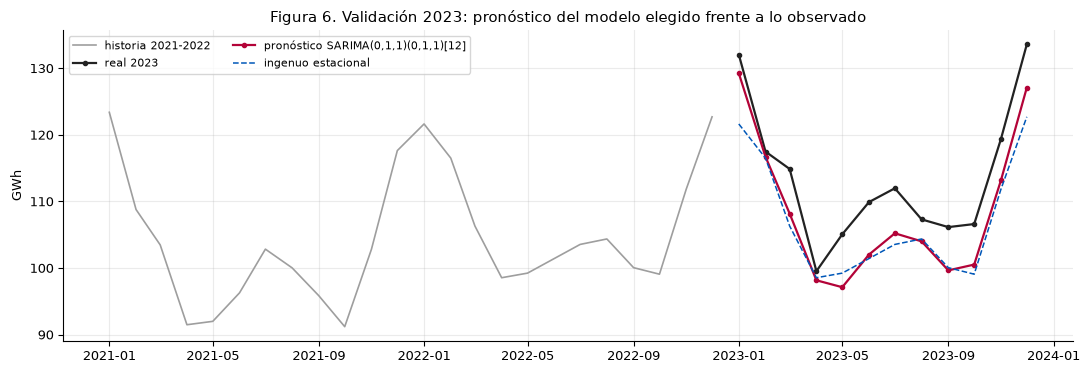

In [19]:
# ============================================================
# 5.4 Estimación del modelo final: coeficientes e inspección de la validación
# ============================================================
print(res_sel.summary().tables[1])

fig, ax = plt.subplots(figsize=(11, 3.8))
hist = y_aj.loc["2021-01-01":"2022-12-01"]
ax.plot(hist, color=GRIS, lw=1.2, label="historia 2021-2022")
ax.plot(real_val, color=NEGRO, lw=1.6, marker="o", ms=3, label="real 2023")
ax.plot(sel["pred_val"], color=ROJO, lw=1.6, marker="o", ms=3, label=f"pronóstico {seleccion}")
ax.plot(naive_val, color=AZUL, lw=1.1, ls="--", label="ingenuo estacional")
ax.set_ylabel("GWh"); ax.legend(fontsize=8, ncol=2)
ax.set_title("Figura 6. Validación 2023: pronóstico del modelo elegido frente a lo observado")
plt.tight_layout(); plt.show()

Tabla 9. Prueba final 2024 (GWh); escala MASE = 6.49 GWh


,RMSE,MAE,MAPE,MASE,sesgo %
"SARIMA(0,1,1)(0,1,1)[12]",4.442,3.540,2.884,0.546,-2.046
Ingenuo estacional,8.193,6.666,5.397,1.027,-5.321


Cobertura del intervalo de 95 %: 92 % de los 12 meses


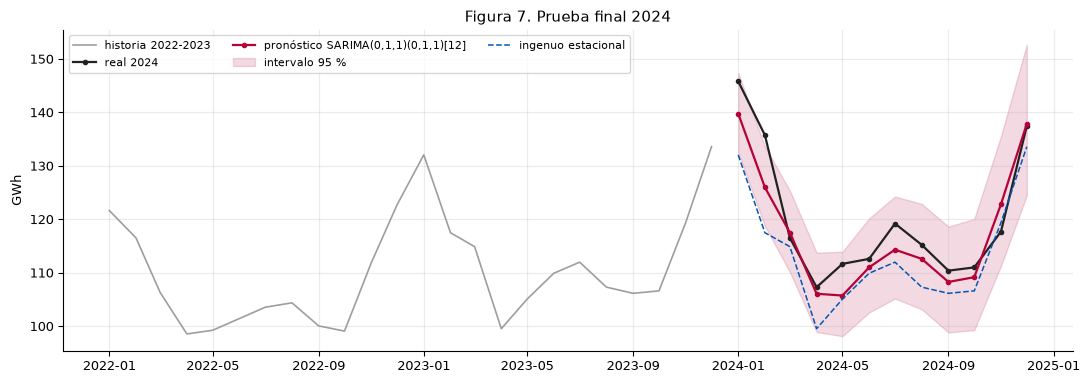


**Lectura (Tabla 9 y Figura 7).** En 2024 el modelo SARIMA(0,1,1)(0,1,1)[12] obtiene RMSE = 4,44 GWh, MAPE = 2,88 % y MASE = 0,55; el ingenuo estacional obtiene RMSE = 8,19 GWh y MASE = 1,03. El modelo **supera** al ingenuo estacional en RMSE. El sesgo promedio del pronóstico es -2,0 % (subestima el consumo), y el intervalo de 95 % contiene 92 % de los meses observados.
El sesgo es pequeño.


In [20]:
# ============================================================
# 5.5 Prueba final con el año 2024 (se usa una sola vez, con el modelo ya elegido)
# ============================================================
pred_t, lo_t, hi_t = pronosticar(res_sel, 12, X_prueba)   # res_sel está estimado con 2015-2023
pred_t = pd.Series(pred_t, index=prueba_2024.index)
lo_t = pd.Series(lo_t, index=prueba_2024.index); hi_t = pd.Series(hi_t, index=prueba_2024.index)
naive_t = pd.Series(y_aj.loc["2023-01-01":"2023-12-01"].values, index=prueba_2024.index)
escala_t = float(y_aj.diff(S).dropna().abs().mean())

m_test = pd.DataFrame({seleccion: metricas(prueba_2024, pred_t, escala_t),
                       "Ingenuo estacional": metricas(prueba_2024, naive_t, escala_t)}).T
cobertura = float(((prueba_2024 >= lo_t) & (prueba_2024 <= hi_t)).mean() * 100)
print(f"Tabla 9. Prueba final 2024 (GWh); escala MASE = {escala_t:.2f} GWh")
display(m_test.round(3))
print(f"Cobertura del intervalo de 95 %: {cobertura:.0f} % de los 12 meses")

fig, ax = plt.subplots(figsize=(11, 3.9))
ax.plot(y_aj.loc["2022-01-01":], color=GRIS, lw=1.2, label="historia 2022-2023")
ax.plot(prueba_2024, color=NEGRO, lw=1.6, marker="o", ms=3, label="real 2024")
ax.plot(pred_t, color=ROJO, lw=1.6, marker="o", ms=3, label=f"pronóstico {seleccion}")
ax.fill_between(pred_t.index, lo_t, hi_t, color=ROJO, alpha=0.15, label="intervalo 95 %")
ax.plot(naive_t, color=AZUL, lw=1.1, ls="--", label="ingenuo estacional")
ax.set_ylabel("GWh"); ax.legend(fontsize=8, ncol=3, loc="upper left")
ax.set_title("Figura 7. Prueba final 2024")
plt.tight_layout(); plt.show()

mejor = m_test.loc[seleccion, "RMSE"] < m_test.loc["Ingenuo estacional", "RMSE"]
sesgo_t = m_test.loc[seleccion, "sesgo %"]
display(Markdown(f"""
**Lectura (Tabla 9 y Figura 7).** En 2024 el modelo {seleccion} obtiene RMSE = {c(m_test.loc[seleccion, 'RMSE'])} GWh, MAPE = {c(m_test.loc[seleccion, 'MAPE'])} % y MASE = {c(m_test.loc[seleccion, 'MASE'])}; el ingenuo estacional obtiene RMSE = {c(m_test.loc['Ingenuo estacional', 'RMSE'])} GWh y MASE = {c(m_test.loc['Ingenuo estacional', 'MASE'])}. El modelo {'**supera**' if mejor else '**no supera**'} al ingenuo estacional en RMSE. El sesgo promedio del pronóstico es {c(sesgo_t, 1)} % ({'sobreestima' if sesgo_t > 0 else 'subestima'} el consumo), y el intervalo de 95 % contiene {c(cobertura, 0)} % de los meses observados.
{'El sesgo es pequeño.' if abs(sesgo_t) < 3 else 'El sesgo es relevante: en 2024 el consumo real se alejó de lo que extrapola el modelo, por ejemplo por un crecimiento distinto del que arrastra la tendencia estimada. Esto es una limitación de los modelos univariados, que solo proyectan el pasado.'}
"""))

> **Interpretación del autor — Sección 5 (selección y comparación).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Por qué el modelo elegido es mejor que los demás según AIC, BIC y los errores de pronóstico, y dónde hubo conflicto entre criterios?
> - ¿Qué significa para el negocio que el modelo supere (o no) al pronóstico ingenuo estacional?
> - ¿Qué me dice el resultado de 2024 sobre la confianza que puedo tener en el modelo?
>
> **[COMPLETAR]**

# 6. Diagnóstico de residuos y validación de supuestos

Un modelo ARIMA/SARIMA es válido cuando sus **residuos se comportan como ruido blanco**. Eso significa tres cosas, y reviso cada una con un test y un gráfico:

1. **Sin autocorrelación:** si quedara dependencia en los residuos, el modelo habría dejado información sin aprovechar. Uso el test de **Ljung-Box** (H₀: no hay autocorrelación) con los grados de libertad ajustados por la cantidad de parámetros ARMA estimados, y la ACF de los residuos.
2. **Normalidad:** los intervalos de pronóstico asumen errores normales. Uso **Jarque-Bera** (Jarque y Bera, 1987) y **Shapiro-Wilk** (Shapiro y Wilk, 1965), junto con un gráfico Q-Q y el histograma (H₀: los residuos son normales).
3. **Varianza constante (homocedasticidad):** uso el test **ARCH de Engle** (1982) (H₀: no hay efecto ARCH) y una comparación de varianzas entre la primera y la segunda mitad de los residuos con un test F (H₀: misma varianza).

Además verifico que los residuos tengan **media cero** con un test t. Con las primeras observaciones no se trabaja, porque la diferenciación las deja sin pronóstico válido (se descartan las primeras d + D·12 observaciones).

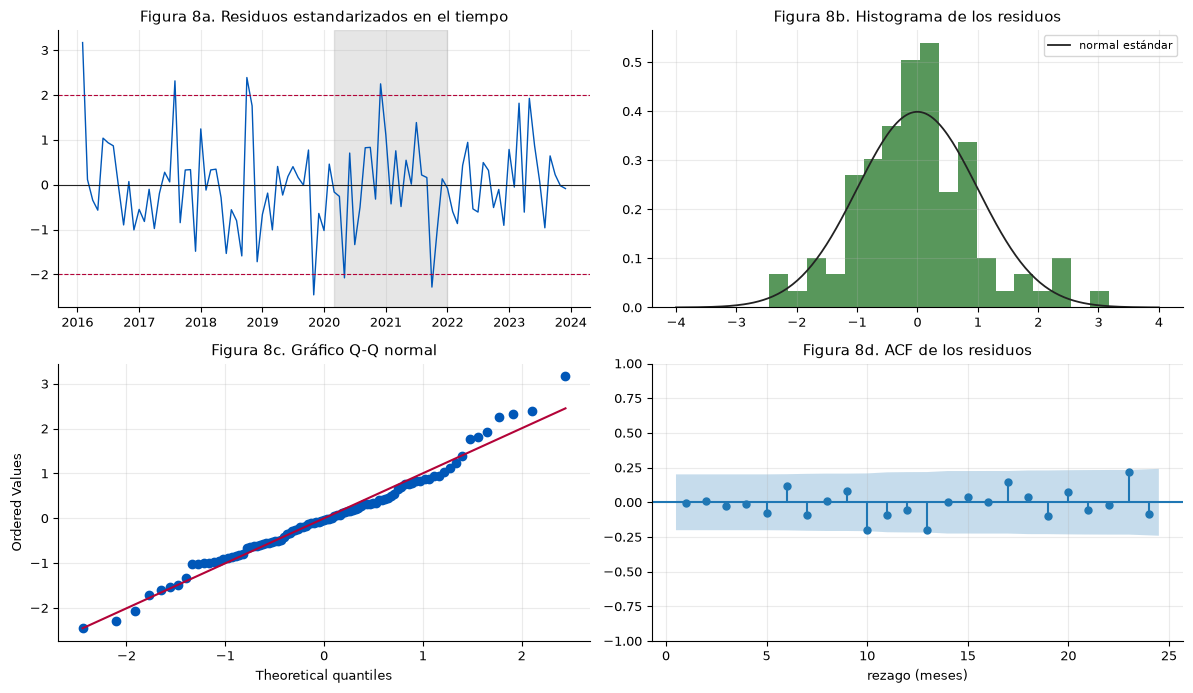

Residuos usados: 95 (se descartan los primeros 13)
Meses con |residuo estandarizado| > 2: {'2016-02': 3.17, '2017-08': 2.32, '2018-10': 2.39, '2019-11': -2.46, '2020-05': -2.08, '2020-12': 2.25, '2021-10': -2.28}


In [21]:
# ============================================================
# 6.1 Residuos del modelo final: serie, histograma, Q-Q y ACF
# ============================================================
e = res_sel.resid.iloc[BURN:].copy()                       # residuos válidos (se excluye el arranque de la diferenciación)
z = (e - e.mean()) / e.std()                               # residuos estandarizados

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].plot(z, color=AZUL, lw=1.0)
axes[0, 0].axhline(0, color=NEGRO, lw=0.8)
for lim in (-2, 2):
    axes[0, 0].axhline(lim, color=ROJO, ls="--", lw=0.8)
axes[0, 0].axvspan(COVID_INI, COVID_FIN, color=GRIS, alpha=0.25)
axes[0, 0].set_title("Figura 8a. Residuos estandarizados en el tiempo")

axes[0, 1].hist(z, bins=18, density=True, color=VERDE, alpha=0.8)
xs = np.linspace(-4, 4, 200)
axes[0, 1].plot(xs, stats.norm.pdf(xs), color=NEGRO, lw=1.3, label="normal estándar")
axes[0, 1].legend(fontsize=8); axes[0, 1].set_title("Figura 8b. Histograma de los residuos")

stats.probplot(z, dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Figura 8c. Gráfico Q-Q normal")
axes[1, 0].get_lines()[0].set_markerfacecolor(AZUL); axes[1, 0].get_lines()[0].set_markeredgecolor(AZUL)
axes[1, 0].get_lines()[1].set_color(ROJO)

plot_acf(e, lags=24, ax=axes[1, 1], zero=False, title="Figura 8d. ACF de los residuos")
axes[1, 1].set_xlabel("rezago (meses)")
plt.tight_layout(); plt.show()

# Meses con residuos grandes (|z| > 2)
grandes = z[z.abs() > 2].round(2)
print(f"Residuos usados: {len(e)} (se descartan los primeros {BURN})")
print("Meses con |residuo estandarizado| > 2:", {f"{k:%Y-%m}": float(v) for k, v in grandes.items()} if len(grandes) else "ninguno")

In [22]:
# ============================================================
# 6.2 Tests: autocorrelación, normalidad, homocedasticidad y media cero
# ============================================================
k_arma = sel["k_arma"]
lags_lb = [lag for lag in (6, 12, 18, 24) if lag > k_arma]
lb = acorr_ljungbox(e, lags=lags_lb, model_df=k_arma, return_df=True)
lb.index.name = "rezagos"
lb = lb.rename(columns={"lb_stat": "estadístico Q", "lb_pvalue": "valor-p"})
lb["conclusión (5 %)"] = np.where(lb["valor-p"] > 0.05, "no rechaza H0 (sin autocorrelación)", "rechaza H0 (hay autocorrelación)")
print(f"Tabla 10. Test de Ljung-Box (grados de libertad ajustados por {k_arma} parámetros ARMA)")
display(lb.round(3))

jb_est, jb_p = stats.jarque_bera(e)
sw_est, sw_p = stats.shapiro(e)
asimetria, curtosis = float(stats.skew(e)), float(stats.kurtosis(e))     # curtosis en exceso (normal = 0)
arch_lm, arch_p, _, _ = het_arch(e, nlags=12)

# Test F de igualdad de varianzas: segunda mitad frente a primera mitad
mitad = len(e) // 2
v1, v2 = float(e.iloc[:mitad].var(ddof=1)), float(e.iloc[mitad:].var(ddof=1))
F = v2 / v1
p_F = 2 * min(stats.f.cdf(F, len(e) - mitad - 1, mitad - 1), 1 - stats.f.cdf(F, len(e) - mitad - 1, mitad - 1))
t_est, t_p = stats.ttest_1samp(e, 0.0)

resumen = pd.DataFrame([
    {"supuesto": "Sin autocorrelación", "test": f"Ljung-Box (rezago {lags_lb[-1]})", "estadístico": lb["estadístico Q"].iloc[-1], "valor-p": lb["valor-p"].iloc[-1]},
    {"supuesto": "Normalidad", "test": "Jarque-Bera", "estadístico": jb_est, "valor-p": jb_p},
    {"supuesto": "Normalidad", "test": "Shapiro-Wilk", "estadístico": sw_est, "valor-p": sw_p},
    {"supuesto": "Homocedasticidad", "test": "ARCH de Engle (12 rezagos)", "estadístico": arch_lm, "valor-p": arch_p},
    {"supuesto": "Homocedasticidad", "test": "F de varianzas (2.ª / 1.ª mitad)", "estadístico": F, "valor-p": p_F},
    {"supuesto": "Media cero", "test": "t de Student", "estadístico": t_est, "valor-p": t_p},
])
resumen["conclusión (5 %)"] = np.where(resumen["valor-p"] > 0.05, "Cumple", "No cumple")
print("Tabla 11. Resumen de los supuestos de los residuos")
display(resumen.round(3))
print(f"Asimetría = {asimetria:.2f} · curtosis en exceso = {curtosis:.2f} · varianza 1.ª mitad = {v1:.5f} · varianza 2.ª mitad = {v2:.5f}")

Tabla 10. Test de Ljung-Box (grados de libertad ajustados por 2 parámetros ARMA)


,estadístico Q,valor-p,conclusión (5 %)
rezagos,,,
6,2.075,0.722,no rechaza H0 (sin autocorrelación)
12,9.373,0.497,no rechaza H0 (sin autocorrelación)
18,16.713,0.404,no rechaza H0 (sin autocorrelación)
24,26.217,0.242,no rechaza H0 (sin autocorrelación)


Tabla 11. Resumen de los supuestos de los residuos


,supuesto,test,estadístico,valor-p,conclusión (5 %)
0,Sin autocorrelación,Ljung-Box (rezago 24),26.217,0.242,Cumple
1,Normalidad,Jarque-Bera,5.166,0.076,Cumple
2,Normalidad,Shapiro-Wilk,0.979,0.124,Cumple
3,Homocedasticidad,ARCH de Engle (12 rezagos),6.953,0.861,Cumple
4,Homocedasticidad,F de varianzas (2.ª / 1.ª mitad),0.724,0.274,Cumple
5,Media cero,t de Student,-0.924,0.358,Cumple


Asimetría = 0.38 · curtosis en exceso = 0.85 · varianza 1.ª mitad = 0.00103 · varianza 2.ª mitad = 0.00075


In [23]:
# ============================================================
# 6.3 Interpretación automática de los resultados
# ============================================================
ok_lb = bool((lb["valor-p"] > 0.05).all())
ok_norm = (jb_p > 0.05) and (sw_p > 0.05)
ok_het = (arch_p > 0.05) and (p_F > 0.05)
ok_media = t_p > 0.05
lb_min = float(lb["valor-p"].min())
cuantos_acf = int((np.abs(acf(e, nlags=24)[1:]) > 1.96 / np.sqrt(len(e))).sum())

t_lb = (f"**Autocorrelación.** El test de Ljung-Box da valores-p entre {pv(lb_min)} y {pv(float(lb['valor-p'].max()))} en los rezagos {lags_lb}. "
        + ("Ningún valor-p está bajo 0,05, así que no se rechaza que los residuos sean ruido blanco: el modelo capturó la dependencia temporal de la serie. "
           if ok_lb else
           "Al menos un valor-p está bajo 0,05, así que hay autocorrelación residual: el modelo no capturó toda la dependencia. ")
        + f"La ACF de los residuos tiene {cuantos_acf} de 24 rezagos fuera de la banda de ±1,96/√n (con 24 rezagos se esperaría cerca de 1 por azar).")

t_nm = (f"**Normalidad.** Jarque-Bera da p = {pv(jb_p)} y Shapiro-Wilk p = {pv(sw_p)}; la asimetría es {c(asimetria)} y la curtosis en exceso {c(curtosis)}. "
        + ("No se rechaza la normalidad, de modo que los intervalos de pronóstico son razonables."
           if ok_norm else
           "Se rechaza la normalidad en al menos uno de los tests. "
           + ("Las colas son más pesadas que las de una normal (curtosis positiva), algo que suelen provocar los meses extremos del COVID-19. " if curtosis > 0 else "")
           + "Los pronósticos puntuales siguen siendo útiles, pero los intervalos de 95 % deben leerse como aproximados."))

t_ht = (f"**Homocedasticidad.** El test ARCH da p = {pv(arch_p)} y el test F entre mitades da p = {pv(p_F)} (varianza de la primera mitad {c(v1, 5)} frente a {c(v2, 5)} en la segunda). "
        + ("No hay evidencia de varianza cambiante, y el logaritmo cumplió su función de estabilizar la variabilidad."
           if ok_het else
           "Hay evidencia de que la varianza cambia en el tiempo, lo que se asocia con el periodo del COVID-19; un modelo con varianza condicional (por ejemplo, GARCH) sería una mejora futura."))

t_md = f"**Media.** El test t da p = {pv(t_p)}: " + ("la media de los residuos no difiere de cero." if ok_media else "la media de los residuos difiere de cero.")

n_ok = sum([ok_lb, ok_norm, ok_het, ok_media])
if ok_lb and ok_het:
    veredicto = ("**el modelo es válido para pronosticar**: sus residuos no tienen autocorrelación y su varianza es estable, que son los supuestos que más "
                 "importan para el pronóstico puntual" + ("; además los residuos son normales, por lo que también los intervalos son confiables." if ok_norm
                 else ". La normalidad no se cumple del todo, así que los intervalos de confianza deben usarse con cautela."))
elif ok_lb:
    veredicto = ("**el modelo es válido con reservas**: no queda autocorrelación, pero la varianza no es constante, así que la incertidumbre de los pronósticos "
                 "puede estar mal calibrada.")
else:
    veredicto = ("**el modelo es válido solo de forma parcial**: queda autocorrelación en los residuos, por lo que existe estructura que el modelo no "
                 "captura y convendría enriquecerlo (más términos AR/MA, mejor tratamiento del COVID-19 o una variable explicativa como la temperatura).")

display(Markdown(f"""
**Lectura de las Figuras 8a-8d y de las Tablas 10 y 11.**

{t_lb}

{t_nm}

{t_ht}

{t_md}

**Conclusión del diagnóstico.** De los cuatro grupos de supuestos revisados (autocorrelación, normalidad, homocedasticidad y media cero), se cumplen {n_ok} de 4. En resumen, {veredicto}
"""))


**Lectura de las Figuras 8a-8d y de las Tablas 10 y 11.**

**Autocorrelación.** El test de Ljung-Box da valores-p entre 0,242 y 0,722 en los rezagos [6, 12, 18, 24]. Ningún valor-p está bajo 0,05, así que no se rechaza que los residuos sean ruido blanco: el modelo capturó la dependencia temporal de la serie. La ACF de los residuos tiene 2 de 24 rezagos fuera de la banda de ±1,96/√n (con 24 rezagos se esperaría cerca de 1 por azar).

**Normalidad.** Jarque-Bera da p = 0,076 y Shapiro-Wilk p = 0,124; la asimetría es 0,38 y la curtosis en exceso 0,85. No se rechaza la normalidad, de modo que los intervalos de pronóstico son razonables.

**Homocedasticidad.** El test ARCH da p = 0,861 y el test F entre mitades da p = 0,274 (varianza de la primera mitad 0,00103 frente a 0,00075 en la segunda). No hay evidencia de varianza cambiante, y el logaritmo cumplió su función de estabilizar la variabilidad.

**Media.** El test t da p = 0,358: la media de los residuos no difiere de cero.

**Conclusión del diagnóstico.** De los cuatro grupos de supuestos revisados (autocorrelación, normalidad, homocedasticidad y media cero), se cumplen 4 de 4. En resumen, **el modelo es válido para pronosticar**: sus residuos no tienen autocorrelación y su varianza es estable, que son los supuestos que más importan para el pronóstico puntual; además los residuos son normales, por lo que también los intervalos son confiables.


## 6.4 Robustez: ¿cambia algo si no se modela el COVID-19?

Para justificar el uso de los regresores del COVID-19, comparo el modelo final con el mismo modelo estimado **sin** esos regresores. Si los indicadores aportan, el AIC debería bajar y los residuos deberían mejorar.

In [24]:
# ============================================================
# 6.4 Mismo modelo sin regresores del COVID-19
# ============================================================
res_nc = ajustar(ly, None, spec_sel)
e_nc = res_nc.resid.iloc[BURN:]
lb_nc = acorr_ljungbox(e_nc, lags=[lag for lag in (12, 24) if lag > k_arma], model_df=k_arma, return_df=True)
lb_c = acorr_ljungbox(e, lags=[lag for lag in (12, 24) if lag > k_arma], model_df=k_arma, return_df=True)
jb_nc = stats.jarque_bera(e_nc)[1]
pred_nc, _, _ = pronosticar(res_nc, 12, None)
m_nc = metricas(prueba_2024, pred_nc, escala_t)

comp_rob = pd.DataFrame({
    "con regresores COVID-19": {"AIC": res_sel.aic, "BIC": res_sel.bic, "desv. residuos": float(e.std()),
                                "Ljung-Box p (mín.)": float(lb_c["lb_pvalue"].min()), "Jarque-Bera p": float(jb_p),
                                "RMSE 2024 (GWh)": m_test.loc[seleccion, "RMSE"]},
    "sin regresores COVID-19": {"AIC": res_nc.aic, "BIC": res_nc.bic, "desv. residuos": float(e_nc.std()),
                                "Ljung-Box p (mín.)": float(lb_nc["lb_pvalue"].min()), "Jarque-Bera p": float(jb_nc),
                                "RMSE 2024 (GWh)": m_nc["RMSE"]},
}).round(4)
print("Tabla 12. Modelo final con y sin regresores del COVID-19")
display(comp_rob)

mejora_aic = float(res_nc.aic - res_sel.aic)
display(Markdown(f"""
**Lectura.** Incluir los regresores {'reduce' if mejora_aic > 0 else 'aumenta'} el AIC en {c(abs(mejora_aic))} puntos y la desviación estándar de los residuos pasa de {c(e_nc.std(), 4)} a {c(e.std(), 4)}. {'Esto respalda tratar el COVID-19 de forma explícita, porque es un shock real que el modelo no puede explicar con su dinámica normal.' if mejora_aic > 2 else 'La diferencia es pequeña, por lo que el modelo es relativamente robusto al tratamiento del COVID-19.'} El pronóstico de 2024 casi no depende de este tratamiento (RMSE de {c(m_test.loc[seleccion, 'RMSE'])} frente a {c(m_nc['RMSE'])} GWh), porque en 2024 los regresores valen cero.
"""))

Tabla 12. Modelo final con y sin regresores del COVID-19


,con regresores COVID-19,sin regresores COVID-19
AIC,-391.0763,-345.3450
BIC,-378.3069,-337.6833
desv. residuos,0.0297,0.0378
Ljung-Box p (mín.),0.2425,0.6909
Jarque-Bera p,0.0756,0.0004
RMSE 2024 (GWh),4.4420,4.7663



**Lectura.** Incluir los regresores reduce el AIC en 45,73 puntos y la desviación estándar de los residuos pasa de 0,0378 a 0,0297. Esto respalda tratar el COVID-19 de forma explícita, porque es un shock real que el modelo no puede explicar con su dinámica normal. El pronóstico de 2024 casi no depende de este tratamiento (RMSE de 4,44 frente a 4,77 GWh), porque en 2024 los regresores valen cero.


> **Interpretación del autor — Sección 6 (diagnóstico de residuos).** *(Escribir con mis propias palabras, de 4 a 6 líneas. Este espacio es parte de mi trabajo personal y no se genera con código ni con IA.)*
>
> - ¿Qué supuestos se cumplieron y cuáles no, y con qué prueba o gráfico lo comprobé?
> - Si algún supuesto falló, ¿qué consecuencia tiene para los pronósticos y los intervalos?
> - ¿Qué mejora concreta propondría para el modelo?
>
> **[COMPLETAR]**

# 7. Conclusiones

Las conclusiones usan los resultados calculados en las secciones anteriores.

In [25]:
# ============================================================
# 7. Conclusiones (se generan con los resultados del notebook)
# ============================================================
cierre_val = ("es válido para pronosticar" if (ok_lb and ok_het) else
              "es válido con reservas" if ok_lb else "es válido solo de forma parcial")
sup = "superó" if mejor else "no superó"

display(Markdown(f"""
1. **Estacionariedad.** En nivel, la serie en logaritmos recibe el veredicto «{pruebas[(0, 0)]['veredicto'].lower()}» (ADF p = {pv(pruebas[(0, 0)]['ADF p'])}, KPSS p = {pv(pruebas[(0, 0)]['KPSS p'])}) y conserva una estacionalidad fuerte (ACF(12) = {c(pruebas[(0, 0)]['ACF(12)'])}). Tras aplicar d = {d_sel} y D = {D_sel} el veredicto es «{pruebas[(d_sel, D_sel)]['veredicto'].lower()}» (ADF p = {pv(pruebas[(d_sel, D_sel)]['ADF p'])}, KPSS p = {pv(pruebas[(d_sel, D_sel)]['KPSS p'])}).

2. **Identificación.** La ACF y la PACF de la serie estacionaria sugirieron un modelo SARIMA({p_sug},{d_sel},{q_sug})({P_sug},{D_sel},{Q_sug})₁₂ como punto de partida. Se estimaron {len(tabla)} candidatos de las familias AR, MA, ARMA, ARIMA y SARIMA, todos con regresores para el COVID-19.

3. **Selección.** El modelo elegido fue **{seleccion}**, con AIC = {c(fila_sel['AIC'])}, BIC = {c(fila_sel['BIC'])} y MASE de validación = {c(fila_sel['MASE_val'])} (el ingenuo estacional tuvo {c(fila_naive['MASE_val'])}). En la validación 2023 su RMSE fue {c(fila_sel['RMSE_val'])} GWh.

4. **Prueba final 2024.** El modelo tuvo RMSE = {c(m_test.loc[seleccion, 'RMSE'])} GWh y MAPE = {c(m_test.loc[seleccion, 'MAPE'])} %, y {sup} al ingenuo estacional en RMSE ({c(m_test.loc['Ingenuo estacional', 'RMSE'])} GWh). El sesgo fue {c(m_test.loc[seleccion, 'sesgo %'], 1)} % y el intervalo de 95 % cubrió el {c(cobertura, 0)} % de los meses.

5. **Residuos.** Ljung-Box {'no detecta' if ok_lb else 'detecta'} autocorrelación; la normalidad {'se cumple' if ok_norm else 'no se cumple del todo'}; la homocedasticidad {'se cumple' if ok_het else 'no se cumple del todo'}. En conjunto, el modelo {cierre_val}.

6. **Para el negocio.** {'Para decidir cuánta energía contratar, el pronóstico puntual del modelo sirve como base y el intervalo de 95 % indica un margen de seguridad para planificar.' if ok_lb else 'Antes de usar el modelo para contratar energía conviene mejorarlo, porque aún queda estructura en los residuos; mientras tanto, el pronóstico puede usarse como referencia junto con el ingenuo estacional.'}
"""))


1. **Estacionariedad.** En nivel, la serie en logaritmos recibe el veredicto «discrepante / no concluyente» (ADF p = 0,553, KPSS p = 0,100) y conserva una estacionalidad fuerte (ACF(12) = 0,62). Tras aplicar d = 1 y D = 1 el veredicto es «estacionaria» (ADF p = < 0,001, KPSS p = 0,100).

2. **Identificación.** La ACF y la PACF de la serie estacionaria sugirieron un modelo SARIMA(0,1,0)(0,1,1)₁₂ como punto de partida. Se estimaron 16 candidatos de las familias AR, MA, ARMA, ARIMA y SARIMA, todos con regresores para el COVID-19.

3. **Selección.** El modelo elegido fue **SARIMA(0,1,1)(0,1,1)[12]**, con AIC = -391,08, BIC = -378,31 y MASE de validación = 0,81 (el ingenuo estacional tuvo 1,01). En la validación 2023 su RMSE fue 5,75 GWh.

4. **Prueba final 2024.** El modelo tuvo RMSE = 4,44 GWh y MAPE = 2,88 %, y superó al ingenuo estacional en RMSE (8,19 GWh). El sesgo fue -2,0 % y el intervalo de 95 % cubrió el 92 % de los meses.

5. **Residuos.** Ljung-Box no detecta autocorrelación; la normalidad se cumple; la homocedasticidad se cumple. En conjunto, el modelo es válido para pronosticar.

6. **Para el negocio.** Para decidir cuánta energía contratar, el pronóstico puntual del modelo sirve como base y el intervalo de 95 % indica un margen de seguridad para planificar.


### Limitaciones y trabajo futuro

- **Pocos datos y un shock grande.** Son solo 9 años de datos y dos de ellos están afectados por el COVID-19; esto limita la precisión de la estimación estacional y de los tests de raíz unitaria, que pueden confundir un quiebre con una raíz unitaria.
- **Modelo univariado.** No usa la temperatura, que en la Sumativa 1 mostró la relación más fuerte con el consumo (ρ = +0,69). Un modelo SARIMAX con temperatura podría mejorar el pronóstico, pero exigiría pronosticar también la temperatura.
- **Datos sintéticos.** Las interpretaciones sobre las causas del consumo son hipótesis, no hechos.
- **Selección de candidatos.** Probé una lista acotada de modelos y no una búsqueda exhaustiva. Otros órdenes podrían ajustar un poco mejor, aunque con más riesgo de sobreajuste.
- **Intervalos.** Si la normalidad de los residuos no se cumple, los intervalos de pronóstico son solo aproximados.

## 7.1 Cierre del ciclo con la Sumativa 1

En la sección 6.3 de la Sumativa 1 dejé seis implicancias para el modelamiento. La tabla siguiente indica cómo se abordó cada una en este informe, con los resultados calculados.

In [26]:
# ============================================================
# 7.1 Hoja de ruta de la Sumativa 1 frente a lo realizado en esta Sumativa
# ============================================================
coincide_dif = (d_sel, D_sel) == (1, 1)
hoja = pd.DataFrame([
    ("1. Elegir la transformación (original, log o Box-Cox)",
     f"Sección 3.1: λ de Box-Cox = {c(lam)} y elasticidad = {c(elasticidad)}; se usó logaritmo."),
    ("2. Confirmar d = 1 y D = 1 con ADF y KPSS",
     f"Sección 3.2-3.3: la regla eligió d = {d_sel} y D = {D_sel}. "
     + ("Coincide con lo anticipado en la Sumativa 1." if coincide_dif else
        "Difiere de lo anticipado: la evidencia de los tests (Tabla 1) mostró que no hacía falta la diferenciación adicional, con lo que se evita sobrediferenciar.")),
    ("3. Tratar el quiebre del COVID-19",
     f"Sección 2.3: dos indicadores (periodo y mínimo de 2020); coeficiente del periodo = {c(b_cov, 3)}, del mínimo = {c(b_pico, 3)}."),
    ("4. Tratar el atípico de noviembre de 2017",
     f"Sección 2.3: reemplazado por su valor esperado ({c(esperado)} GWh), como decidí en la Sumativa 1."),
    ("5. Mantener el enfoque univariado (SARIMAX como mejora futura)",
     "Se modeló solo el consumo; la temperatura queda como trabajo futuro (ver limitaciones)."),
    ("6. Superar al pronóstico ingenuo estacional",
     f"Validación 2023: RMSE {c(fila_sel['RMSE_val'])} vs {c(fila_naive['RMSE_val'])} GWh; prueba 2024: RMSE {c(m_test.loc[seleccion, 'RMSE'])} vs {c(m_test.loc['Ingenuo estacional', 'RMSE'])} GWh."),
], columns=["Implicancia (Sumativa 1, sección 6.3)", "Qué se hizo y resultado en esta Sumativa"]).set_index("Implicancia (Sumativa 1, sección 6.3)")
print("Tabla 13. Seguimiento de las implicancias de la Sumativa 1")
display(hoja)

display(Markdown(
    "**Pendiente heredado.** En la Sumativa 1 mencioné evaluar STL (Cleveland et al., 1990) en la etapa de modelamiento. Esta Sumativa se limita a los modelos clásicos ARIMA/SARIMA que pide la evaluación, por lo que STL queda como comparación futura."
))

Tabla 13. Seguimiento de las implicancias de la Sumativa 1


,Qué se hizo y resultado en esta Sumativa
"Implicancia (Sumativa 1, sección 6.3)",
"1. Elegir la transformación (original, log o Box-Cox)","Sección 3.1: λ de Box-Cox = 0,11 y elasticidad..."
2. Confirmar d = 1 y D = 1 con ADF y KPSS,Sección 3.2-3.3: la regla eligió d = 1 y D = 1...
3. Tratar el quiebre del COVID-19,Sección 2.3: dos indicadores (periodo y mínimo...
4. Tratar el atípico de noviembre de 2017,Sección 2.3: reemplazado por su valor esperado...
5. Mantener el enfoque univariado (SARIMAX como mejora futura),Se modeló solo el consumo; la temperatura qued...
6. Superar al pronóstico ingenuo estacional,"Validación 2023: RMSE 5,75 vs 7,29 GWh; prueba..."


**Pendiente heredado.** En la Sumativa 1 mencioné evaluar STL (Cleveland et al., 1990) en la etapa de modelamiento. Esta Sumativa se limita a los modelos clásicos ARIMA/SARIMA que pide la evaluación, por lo que STL queda como comparación futura.

# 8. Referencias

Akaike, H. (1974). A new look at the statistical model identification. *IEEE Transactions on Automatic Control, 19*(6), 716–723. https://doi.org/10.1109/TAC.1974.1100705

Box, G. E. P., Jenkins, G. M., Reinsel, G. C., & Ljung, G. M. (2015). *Time series analysis: Forecasting and control* (5.ª ed.). Wiley.

Cleveland, R. B., Cleveland, W. S., McRae, J. E., & Terpenning, I. (1990). STL: A seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics, 6*(1), 3–73.

Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association, 74*(366), 427–431. https://doi.org/10.1080/01621459.1979.10482531

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Hyndman, R. J., & Koehler, A. B. (2006). Another look at measures of forecast accuracy. *International Journal of Forecasting, 22*(4), 679–688. https://doi.org/10.1016/j.ijforecast.2006.03.001

Jarque, C. M., & Bera, A. K. (1987). A test for normality of observations and regression residuals. *International Statistical Review, 55*(2), 163–172. https://doi.org/10.2307/1403192

Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root: How sure are we that economic time series have a unit root? *Journal of Econometrics, 54*(1–3), 159–178. https://doi.org/10.1016/0304-4076(92)90104-Y

Ljung, G. M., & Box, G. E. P. (1978). On a measure of lack of fit in time series models. *Biometrika, 65*(2), 297–303. https://doi.org/10.1093/biomet/65.2.297

Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136

Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96. https://doi.org/10.25080/Majora-92bf1922-011

Shapiro, S. S., & Wilk, M. B. (1965). An analysis of variance test for normality (complete samples). *Biometrika, 52*(3–4), 591–611. https://doi.org/10.1093/biomet/52.3-4.591

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.

# 9. Declaración de uso de herramientas de IA

Las instrucciones de la evaluación indican que **no se permite** usar IA generativa para producir respuestas completas, y que solo se puede usar para **organizar ideas o mejorar la redacción**, declarando ese uso. Declaro lo siguiente, y el autor debe corregir cualquier fila que no refleje lo que realmente ocurrió.

**Herramienta utilizada:** Claude (Anthropic), asistente de IA generativa. **Fecha de uso:** octubre de 2026. **[COMPLETAR: confirmar herramienta y fecha]**

| Parte del trabajo | Uso de IA declarado | Trabajo propio del autor |
|---|---|---|
| Estructura del informe y orden según la rúbrica | Apoyo para organizar las secciones | Revisión de que se cumpla cada criterio **[COMPLETAR]** |
| Código (carga de datos, tests, modelos, diagnósticos) | Borrador de código con comentarios | Revisión línea a línea, ejecución y comprensión de cada paso **[COMPLETAR]** |
| Textos que se generan al ejecutar (tablas y lecturas automáticas) | Redacción de plantillas que insertan los resultados calculados | Verificación de que cada afirmación coincida con la tabla o el gráfico **[COMPLETAR]** |
| Reglas de decisión (diferenciación, selección del modelo) | Propuesta de reglas | Aceptación o modificación de las reglas con mi criterio **[COMPLETAR]** |
| Interpretación de resultados | **Ninguno** en los recuadros «Interpretación del autor» | Redacción propia de cada recuadro (secciones 3 a 6) |
| Conclusiones y limitaciones | Mejora de redacción | Contenido y juicio propios **[COMPLETAR]** |

**Qué no se delegó.** La elección del problema, la lectura crítica de los resultados, la decisión final del modelo y la redacción de los recuadros de interpretación propia.

**Verificación.** El autor ejecutó el notebook completo (*Run All*), revisó que las tablas y los textos coincidan y comprobó la continuidad con la Sumativa 1 (sección 2.4). **[COMPLETAR: confirmar solo si es cierto]**

# 10. Lista de verificación de formato y entrega

Esta última celda revisa automáticamente algunos requisitos de formato de la evaluación. **Guardar el notebook antes de ejecutarla**, porque lee el archivo guardado para contar palabras, figuras y marcas pendientes. La estimación de páginas es aproximada (unas 450 palabras o 3 figuras por página).

In [27]:
# ============================================================
# 10. Verificación automática de formato y entrega
# ============================================================
import json, re
from glob import glob

archivos = glob("mcdi505_s2*.ipynb") + glob("*/mcdi505_s2*.ipynb")
fila = lambda req, ok, det: {"requisito": req, "estado": "Cumple" if ok else "Revisar", "detalle": det}
res_ver = []

if archivos:
    ruta_nb = archivos[0]
    nb = json.load(open(ruta_nb, encoding="utf-8"))
    md_txt = " ".join("".join(cel["source"]) for cel in nb["cells"] if cel["cell_type"] == "markdown")
    salidas = []
    n_fig = 0
    for cel in nb["cells"]:
        if cel["cell_type"] == "code":
            for o in cel.get("outputs", []):
                if "data" in o:
                    n_fig += int("image/png" in o["data"])
                    salidas.append("".join(o["data"].get("text/markdown", "")) or "".join(o["data"].get("text/plain", "")))
                elif "text" in o:
                    salidas.append("".join(o["text"]))
    palabras = len(re.findall(r"\w+", md_txt)) + len(re.findall(r"\w+", " ".join(salidas)))
    paginas = palabras / 450 + n_fig / 3
    pendientes = md_txt.count("[COMPLETAR")
    res_ver.append(fila("Nombre de archivo mcdi505_s2<inicial><apellido>.ipynb", re.fullmatch(r"mcdi505_s2[a-z]+\.ipynb", Path(ruta_nb).name) is not None, Path(ruta_nb).name))
    res_ver.append(fila("Extensión 10-15 páginas equivalentes", 10 <= paginas <= 15, f"≈ {paginas:.1f} páginas ({palabras} palabras, {n_fig} figuras guardadas)"))
    res_ver.append(fila("Notebook guardado con salidas (ejecutado)", n_fig >= 5, f"{n_fig} figuras en el archivo"))
    res_ver.append(fila("Sin marcas [COMPLETAR] pendientes", pendientes == 0, f"{pendientes} pendientes (interpretaciones del autor y declaración de IA)"))
    res_ver.append(fila("Sección de referencias (APA)", "# 8. Referencias" in md_txt, "presente" if "# 8. Referencias" in md_txt else "falta"))
    res_ver.append(fila("Declaración de uso de IA", "# 9. Declaración de uso de herramientas de IA" in md_txt, "presente"))
else:
    res_ver.append(fila("Notebook guardado en la carpeta de trabajo", False, "no se encontró mcdi505_s2*.ipynb; guardar y volver a ejecutar esta celda"))

res_ver.append(fila("Archivo de datos presente", Path(ruta).exists(), str(ruta)))
res_ver.append(fila("Partición respetada (2024 solo en la sección 5.5)", len(prueba_2024) == 12 and df.index.max() == pd.Timestamp("2023-12-01"), f"entrenamiento hasta {df.index.max():%Y-%m}"))
res_ver.append(fila("Continuidad con la Sumativa 1 (sección 2.4)", n_coinciden == len(tab_s1), f"{n_coinciden} de {len(tab_s1)} resultados coinciden"))
display(pd.DataFrame(res_ver).set_index("requisito"))

,estado,detalle
requisito,,
Nombre de archivo mcdi505_s2<inicial><apellido>.ipynb,Cumple,mcdi505_s2rmoncada.ipynb
Extensión 10-15 páginas equivalentes,Revisar,"≈ 9.1 páginas (4096 palabras, 0 figuras guarda..."
Notebook guardado con salidas (ejecutado),Revisar,0 figuras en el archivo
Sin marcas [COMPLETAR] pendientes,Revisar,11 pendientes (interpretaciones del autor y de...
Sección de referencias (APA),Cumple,presente
Declaración de uso de IA,Cumple,presente
Archivo de datos presente,Cumple,consumo_electrico_litoral.csv
Partición respetada (2024 solo en la sección 5.5),Cumple,entrenamiento hasta 2023-12
Continuidad con la Sumativa 1 (sección 2.4),Cumple,16 de 16 resultados coinciden
